In [1]:
import numpy as np
import torch
import os

from matplotlib import pyplot as plt
import seaborn as sns
from scipy import stats

%load_ext autoreload
%autoreload 2

from utils import generate_run_ID
from place_cells import PlaceCells
from direction_cells import DirectionCells
from trajectory_generator import TrajectoryGenerator
from models import LMN_PaS_Conj_mEC
from trainer import Trainer

### Section 1: load (or train) the model

In [2]:
# Training options and hyperparameters
class Options:
    pass
options = Options()

options.save_dir = './models_4layer/' 
options.n_steps = 1000    # number of training steps
options.epochs = 201       # number of training epochs
options.batch_size = 500      # number of trajectories per batch
options.sequence_length = 20  # number of steps in trajectory
options.learning_rate = 1e-4  # gradient descent learning rate
#early stopping 
options.freeze_pas_patience = 100
options.freeze_pas_min_delta = 1e-8 #0.0001


options.Nd = 128           # number of direction cells
options.Np = 512           # number of place cells
options.Nlmn = 256        # number of LMN cells
options.Npas = 256        # number of PaS cells
options.Ncg = 512         # number of conjuntive mEC cells
options.Ng = 512         # number of mEC cells

options.place_cell_rf = 0.12  # width of place cell center tuning curve (m)
options.surround_scale = 2    # if DoG, ratio of sigma2^2 to sigma1^2
options.direction_cell_rf = 30*np.pi/180  # width of direction cell tuning curve (radians)
options.activation = 'relu'   # recurrent nonlinearity
options.weight_decay_lmn = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_pas = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_conj = 0 # strength of weight decay on recurrent weights in conj RNN
options.weight_decay_mec = 0  # strength of weight decay on recurrent weights in mEC RNN
options.use_pas_layernorm = False  # apply LayerNorm to PaS before feeding Conj
options.DoG = True            # use difference of gaussians tuning curves
options.periodic = False
options.box_width = 2.2       # width of training environment
options.box_height = 2.2      # height of training environment

options.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

options.run_ID = generate_run_ID(options)

place_cells = PlaceCells(options)
direction_cells = DirectionCells(options)
    
model = LMN_PaS_Conj_mEC(options, direction_cells, place_cells).to(options.device)

trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=place_cells)

ckpt_path = os.path.join(options.save_dir, options.run_ID, 'most_recent_model.pth')

if os.path.exists(ckpt_path):
    trainer = Trainer(options, model, trajectory_generator, restore=True)
    print(f'Checkpoint exists, skip training: {ckpt_path}')
else:
    trainer = Trainer(options, model, trajectory_generator, restore=False)
    trainer.train(n_epochs=options.epochs, n_steps=options.n_steps, save=True)



Restored trained model from ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_201_batch_500_length_20_lr_00001/most_recent_model.pth
Checkpoint exists, skip training: ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_201_batch_500_length_20_lr_00001/most_recent_model.pth


### Section 2: Check angular velocity tuning in either RNN layer 1 and layer 2

Kept 256 cells with |vel_mi| > 1e-08 out of 256


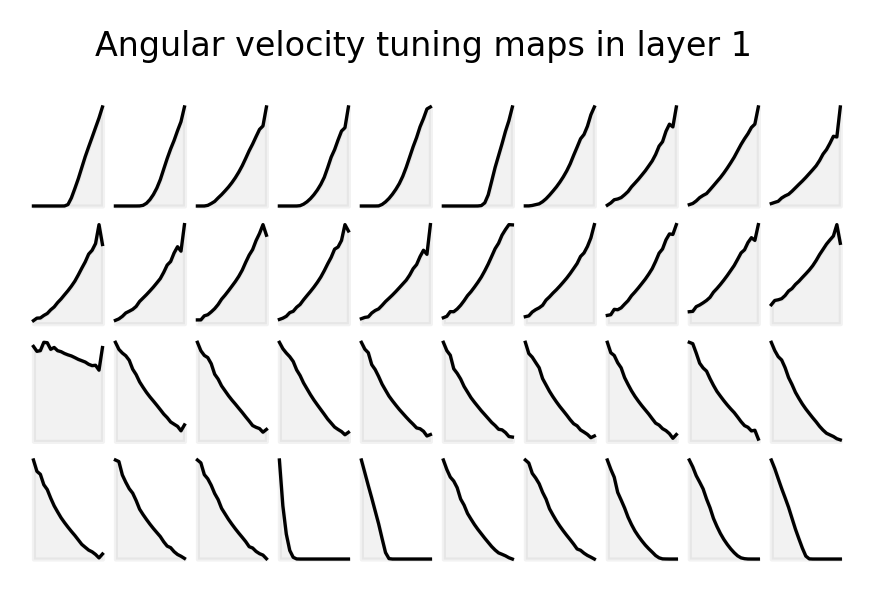

In [3]:
from visualize import compute_angular_velocity_tuning, score_angular_velocity_tuning
import numpy as np
import matplotlib.pyplot as plt

layer = "lmn"
N_layer = options.Npas if layer == "pas" else options.Nlmn

vel_tuning, _, _, ang_v_vals, vel_bin_centers, vel_counts = compute_angular_velocity_tuning(
    model,
    trajectory_generator,
    options,
    res=21,
    n_avg=100,
    N=N_layer,
    use_abs=False,
    layer=layer,
)

vel_mi, tuning_index, vel_peak_bin, vel_peak = score_angular_velocity_tuning(
    vel_tuning, vel_bin_centers
)

# Sort by tuning index, high to low
order = np.argsort(tuning_index)[::-1]
vel_tuning_sorted = vel_tuning[order]
vel_mi_sorted = vel_mi[order]

# Remove cells with weak / zero vel_mi
mi_threshold = 1e-8
valid_mask = np.abs(vel_mi_sorted) > mi_threshold

vel_tuning_tuned = vel_tuning_sorted[valid_mask]
vel_mi_tuned = vel_mi_sorted[valid_mask]
order_tuned = order[valid_mask]

print(
    f"Kept {vel_tuning_tuned.shape[0]} cells with |vel_mi| > {mi_threshold} "
    f"out of {vel_tuning.shape[0]}"
)

# Evenly sample 64 cells from filtered units
n_show = 40
n_cols = 10
n_rows = 4

if vel_tuning_tuned.shape[0] < n_show:
    print(f"Only {vel_tuning_tuned.shape[0]} tuned cells found; plotting all of them.")
    n_show = vel_tuning_tuned.shape[0]

idx_show = np.linspace(
    0,
    vel_tuning_tuned.shape[0] - 1,
    n_show,
    dtype=int,
)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(3.5, 2),
    dpi=300,
    squeeze=False,
)

for i in range(n_rows * n_cols):
    r, c = divmod(i, n_cols)
    ax = axes[r][c]

    if i < n_show:
        idx = idx_show[i]
        vals = vel_tuning_tuned[idx]

        ax.fill_between(vel_bin_centers, 0, vals, color="grey", alpha=0.1)
        ax.plot(vel_bin_centers, vals, color="black", linewidth=0.8)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis("off")

plt.subplots_adjust(wspace=0.08, hspace=0.08)

#add title
if layer == "lmn":
    plt.suptitle(f"Angular velocity tuning maps in layer 1", fontsize=8, y=1)
elif layer == "pas":  
    plt.suptitle(f"Angular velocity tuning maps in layer 2", fontsize=8, y=1)


plt.savefig(
    f"./docs/AHV_tuning_64_{layer}.pdf",
    dpi=300,
    bbox_inches="tight",
)


#### SI figure: all AHV cells in layer 1 and 2

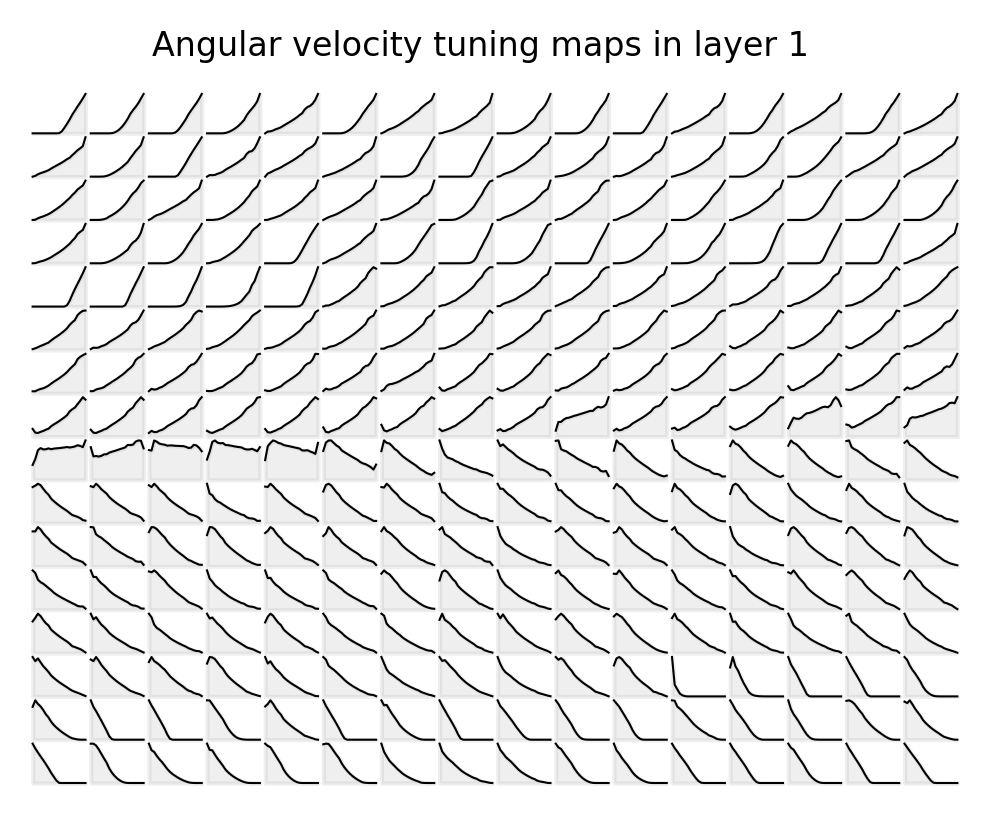

In [4]:
from visualize import compute_angular_velocity_tuning, score_angular_velocity_tuning
import numpy as np
import matplotlib.pyplot as plt

layer = "lmn"
N_layer = options.Npas if layer == "pas" else options.Nlmn

vel_tuning, _, _, ang_v_vals, vel_bin_centers, vel_counts = compute_angular_velocity_tuning(
    model,
    trajectory_generator,
    options,
    res=21,
    n_avg=100,
    N=N_layer,
    use_abs=False,
    layer=layer,
)

vel_mi, tuning_index, vel_peak_bin, vel_peak = score_angular_velocity_tuning(
    vel_tuning, vel_bin_centers
)

# Sort by tuning index, high to low
order = np.argsort(tuning_index)[::-1]
vel_tuning_sorted = vel_tuning[order]
vel_mi_sorted = vel_mi[order]

# Show all 256 cells
n_show = min(256, vel_tuning_sorted.shape[0])
n_cols = 16
n_rows = 16

if vel_tuning_sorted.shape[0] < 256:
    print(f"Only {vel_tuning_sorted.shape[0]} cells found; plotting all of them.")

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4, 3),
    dpi=300,
    squeeze=False,
)

for i in range(n_rows * n_cols):
    r, c = divmod(i, n_cols)
    ax = axes[r][c]

    if i < n_show:
        vals = vel_tuning_sorted[i]

        ax.fill_between(vel_bin_centers, 0, vals, color="grey", alpha=0.12)
        ax.plot(vel_bin_centers, vals, color="black", linewidth=0.5)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis("off")

plt.subplots_adjust(wspace=0., hspace=0.)

if layer == "lmn":
    plt.suptitle("Angular velocity tuning maps in layer 1", fontsize=8, y=0.95)
elif layer == "pas":
    plt.suptitle("Angular velocity tuning maps in layer 2", fontsize=8, y=0.95)

# plt.tight_layout()

plt.savefig(
    f"./docs/AHV_tuning_256_{layer}_SI.pdf",
    dpi=300,
    bbox_inches="tight",
)

### Get the proportion of AHV tuning in layer 1 and 2

LMN AHV tuned: 218/256 (85.2%)
PaS AHV tuned: 158/256 (61.7%)
Fisher exact test: odds ratio = 3.558, p = 2.260e-09


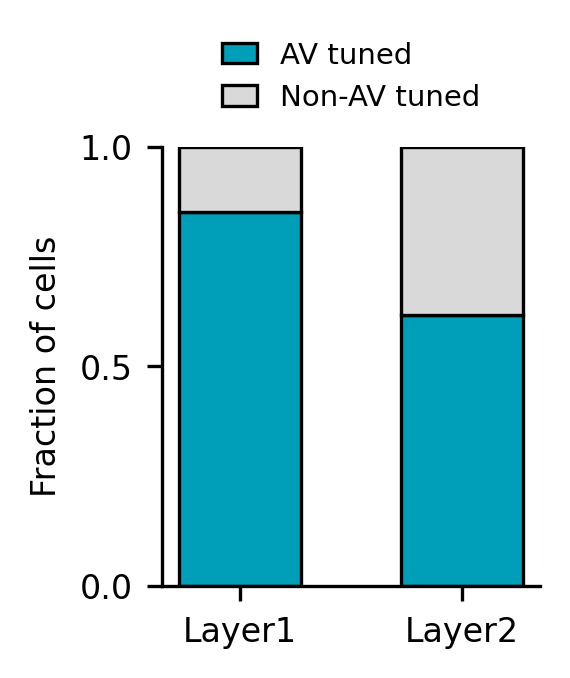

In [5]:

from visualize import compute_angular_velocity_tuning
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(0)

def score_ahv_linear_tuning(vel_tuning, vel_bin_centers, eps=1e-8):
    vals = np.maximum(vel_tuning, 0)
    x = np.asarray(vel_bin_centers, dtype=float)

    x_centered = x - np.mean(x)
    x_var = np.sum(x_centered ** 2) + eps

    slopes = np.zeros(vals.shape[0])
    r2 = np.zeros(vals.shape[0])
    tuning_strength = np.zeros(vals.shape[0])

    for i in range(vals.shape[0]):
        y = vals[i]
        y_mean = np.mean(y)
        y_centered = y - y_mean

        slope = np.sum(y_centered * x_centered) / x_var
        intercept = y_mean - slope * np.mean(x)
        y_hat = intercept + slope * x

        ss_res = np.sum((y - y_hat) ** 2)
        ss_tot = np.sum((y - y_mean) ** 2) + eps
        r2[i] = 1 - ss_res / ss_tot

        slopes[i] = slope

        ymax = np.max(y)
        ymin = np.min(y)
        tuning_strength[i] = (ymax - ymin) / (ymax + ymin + eps)

    signed_tuning_index = np.sign(slopes) * tuning_strength

    return signed_tuning_index, tuning_strength, slopes, r2

def compute_ahv_fraction(layer, ti_thr=0.2, r2_thr=0.5, res=21, n_avg=100):
    N_layer = options.Npas if layer == "pas" else options.Nlmn

    vel_tuning, _, _, ang_v_vals, vel_bin_centers, vel_counts = compute_angular_velocity_tuning(
        model,
        trajectory_generator,
        options,
        res=res,
        n_avg=n_avg,
        N=N_layer,
        use_abs=False,
        layer=layer,
    )

    ahv_ti, ahv_strength, ahv_slope, ahv_r2 = score_ahv_linear_tuning(
        vel_tuning,
        vel_bin_centers,
    )

    ahv_tuned = (np.abs(ahv_ti) > ti_thr) & (ahv_r2 > r2_thr)

    n_total = len(ahv_tuned)
    n_tuned = np.sum(ahv_tuned)
    n_not = n_total - n_tuned

    return {
        "layer": layer,
        "n_total": n_total,
        "n_tuned": n_tuned,
        "n_not": n_not,
        "frac_tuned": n_tuned / n_total,
        "frac_not": n_not / n_total,
        "ahv_tuned": ahv_tuned,
        "ahv_ti": ahv_ti,
        "ahv_r2": ahv_r2,
    }

ti_thr = 0.5
r2_thr = 0.8

lmn_stats = compute_ahv_fraction("lmn", ti_thr=ti_thr, r2_thr=r2_thr)
pas_stats = compute_ahv_fraction("pas", ti_thr=ti_thr, r2_thr=r2_thr)

print(
    f"LMN AHV tuned: {lmn_stats['n_tuned']}/{lmn_stats['n_total']} "
    f"({100 * lmn_stats['frac_tuned']:.1f}%)"
)
print(
    f"PaS AHV tuned: {pas_stats['n_tuned']}/{pas_stats['n_total']} "
    f"({100 * pas_stats['frac_tuned']:.1f}%)"
)

# Fisher exact test for proportion difference
table = np.array([
    [lmn_stats["n_tuned"], lmn_stats["n_not"]],
    [pas_stats["n_tuned"], pas_stats["n_not"]],
])
oddsratio, p_fisher = stats.fisher_exact(table, alternative="two-sided")
print(f"Fisher exact test: odds ratio = {oddsratio:.3f}, p = {p_fisher:.3e}")

# -------------------------
# Plot
# -------------------------
fig, ax = plt.subplots(figsize=(2, 2.5), dpi=300)

x = np.array([0, 1])

frac_tuned = np.array([
    lmn_stats["frac_tuned"],
    pas_stats["frac_tuned"],
])

frac_not = np.array([
    lmn_stats["frac_not"],
    pas_stats["frac_not"],
])

ax.bar(
    x,
    frac_tuned,
    color="#009FB9",
    edgecolor="black",
    linewidth=0.8,
    width=0.55,
    label="AV tuned",
)

ax.bar(
    x,
    frac_not,
    bottom=frac_tuned,
    color="#D9D9D9",
    edgecolor="black",
    linewidth=0.8,
    width=0.55,
    label="Non-AV tuned",
)


ax.set_xticks(x)
ax.set_xticklabels(["Layer1", "Layer2"], fontsize=8)
ax.set_ylabel("Fraction of cells", fontsize=8)
ax.set_ylim(0, 1.0)
ax.set_yticks([0, 0.5, 1.0])
ax.tick_params(axis="y", labelsize=8)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    fontsize=7,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.3),
    ncol=1,
    handlelength=1.2,
)

plt.tight_layout()

plt.savefig(
    "./docs/AHV_tuned_fraction_LMN_PaS_stacked_binary.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()



### Section 3: directional tuning

#### SI figure: all direction tuning

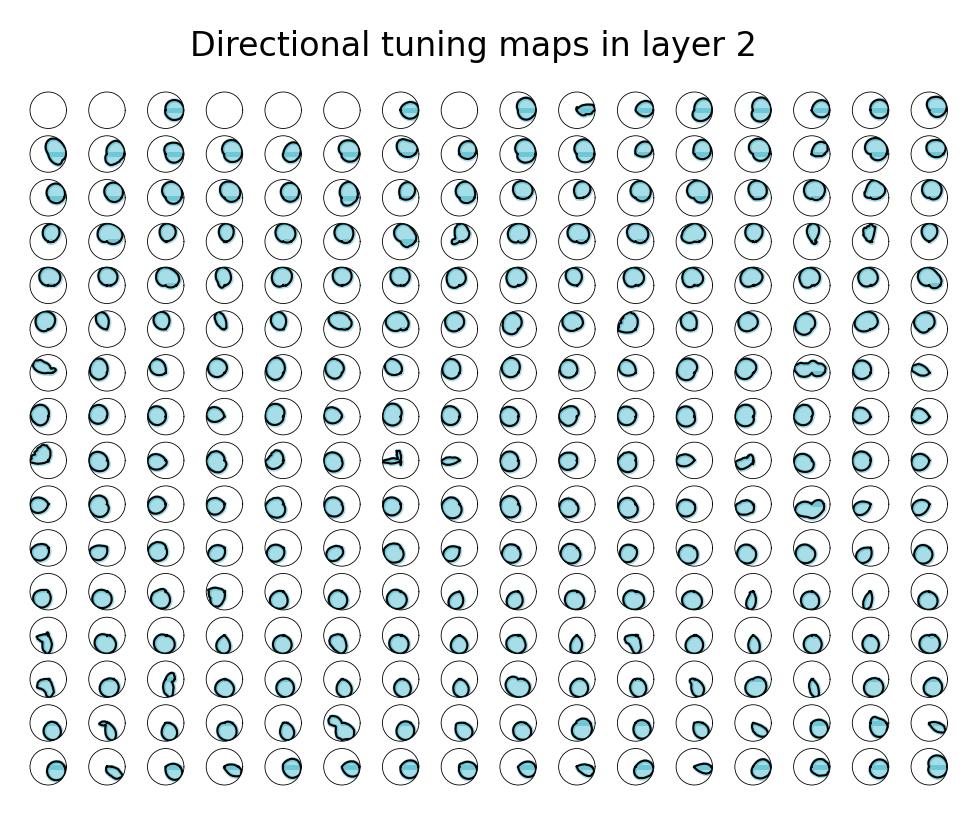

In [6]:
from visualize import compute_ratemaps_lmn_pas_conj_mec

options.sequence_length = 20
options.batch_size = 100

results = compute_ratemaps_lmn_pas_conj_mec(
    model,
    trajectory_generator,
    options,
    res=60,
    n_avg=100,
    N_lmn=options.Nlmn,
    N_pas=options.Npas,
    N_conj=options.Ncg,
    N_mec=options.Ng,
)

(
    activations_lmn_dir,
    rate_map_lmn_dir,
    activations_pas_dir,
    rate_map_pas_dir,
    activations_conj_dir,
    rate_map_conj_dir,
    activations_mec_dir,
    rate_map_mec_dir,
    activations_lmn_spatial,
    rate_map_lmn_spatial,
    activations_pas_spatial,
    rate_map_pas_spatial,
    activations_conj_spatial,
    rate_map_conj_spatial,
    activations_mec_spatial,
    rate_map_mec_spatial,
    lmn,
    pas,
    conj,
    mec,
    ang,
    pos,
) = results


layer = "pas"  # or "pas"

if layer == "lmn":
    activations = activations_lmn_dir
    title = "Directional tuning maps in layer 1"
elif layer == "pas":
    activations = activations_pas_dir
    title = "Directional tuning maps in layer 2"
else:
    raise ValueError("layer must be 'lmn' or 'pas'.")

# 按 preferred direction 排序
pref_idx = np.argmax(activations, axis=1)
order = np.argsort(pref_idx)
activations_sorted = activations[order]

n_plots = activations_sorted.shape[0]
n_cols = 16
n_rows = int(np.ceil(n_plots / n_cols))

fig = plt.figure(figsize=(4,3),dpi=300)
angles = np.linspace(0, 2 * np.pi, activations_sorted.shape[-1], endpoint=False)
angles_closed = np.concatenate([angles, angles[:1] + 2 * np.pi])

for i in range(n_rows * n_cols):
    ax = fig.add_subplot(n_rows, n_cols, i + 1, projection="polar")
    ax.spines["polar"].set_linewidth(0.2)

    if i < n_plots:
        vals = activations_sorted[i]
        vals = np.maximum(vals, 0)
        vals = vals / (np.max(vals) + 1e-8)
        vals_closed = np.concatenate([vals, vals[:1]])

        ax.fill_between(angles_closed, 0, vals_closed, color="#009FB9", alpha=0.35)
        ax.plot(angles_closed, vals_closed, linewidth=0.5, color="black")
        ax.set_ylim(0, 1.0)
    else:
        ax.set_axis_off()

    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(title, fontsize=8, y=0.95)

plt.savefig(
    f"./docs/HD_tuning_256_{layer}_SI.pdf",
    dpi=300,
    bbox_inches="tight",
)

#### SI figure: all spatial tuning in layer 1 and 2

In [7]:
from visualize import rgb, concat_images_in_rows
from imageio import imsave

# LMN spatial
images_lmn = [rgb(im, cmap="jet", smooth=True) for im in activations_lmn_spatial]
lmn_spatial_fig = concat_images_in_rows(
    images_lmn,
    row_size=len(images_lmn) // 16,
    image_width=activations_lmn_spatial.shape[-1],
)
imsave("./docs/spatial_map_lmn.png", lmn_spatial_fig)

# PaS spatial
images_pas = [rgb(im, cmap="jet", smooth=True) for im in activations_pas_spatial]
pas_spatial_fig = concat_images_in_rows(
    images_pas,
    row_size=len(images_pas) // 16,
    image_width=activations_pas_spatial.shape[-1],
)
imsave("./docs/spatial_map_pas.png", pas_spatial_fig)

#### Make a paper figure of angular velocity tuning and cw ccw tuning

/tmp/ipykernel_506163/3916881803.py:294: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


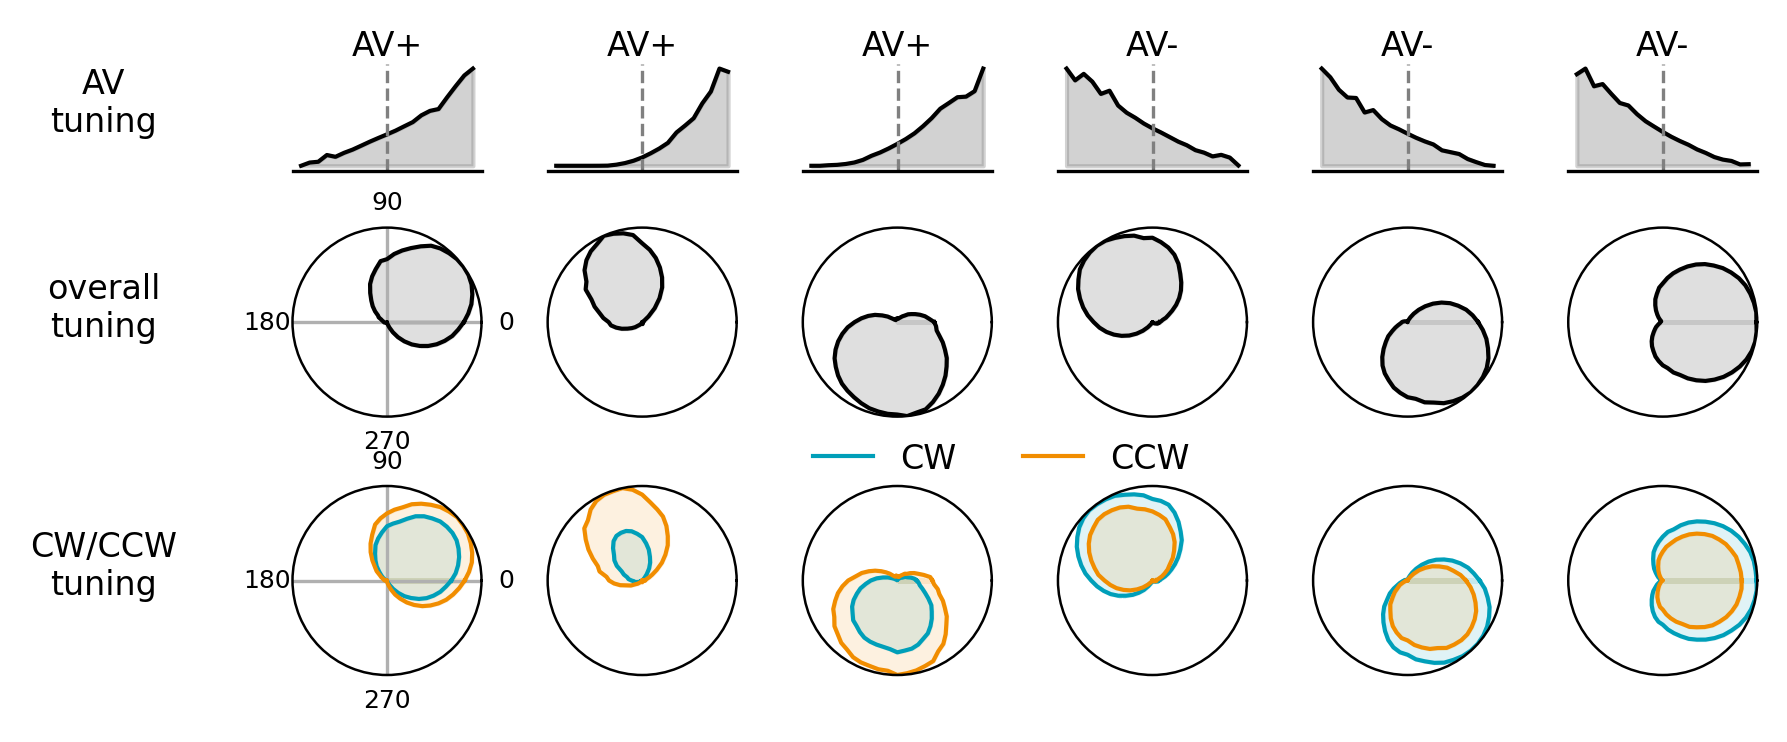

In [8]:
from visualize import (
    compute_angular_velocity_tuning,
    score_angular_velocity_tuning,
    compute_ratemaps_dc_split_by_rotation,
    compute_ratemaps_lmn_pas_conj_mec
)
import numpy as np
import matplotlib.pyplot as plt

options.sequence_length = 20
options.batch_size = 100

# Choose one layer only: "lmn" or "pas"
layer = "lmn"
N_layer = options.Npas if layer == "pas" else options.Nlmn

# -------------------------
# Angular velocity tuning
# -------------------------
vel_tuning, _, _, ang_v_vals, vel_bin_centers, vel_counts = compute_angular_velocity_tuning(
    model,
    trajectory_generator,
    options,
    res=21,
    n_avg=100,
    N=N_layer,
    use_abs=False,
    layer=layer,
)

vel_mi, tuning_index, _, _ = score_angular_velocity_tuning(
    vel_tuning, vel_bin_centers
)

# -------------------------
# Overall direction tuning from mixed-direction ratemaps
# -------------------------
results_overall = compute_ratemaps_lmn_pas_conj_mec(
    model,
    trajectory_generator,
    options,
    res=60,
    n_avg=100,
    N_lmn=options.Nlmn,
    N_pas=options.Npas,
    N_conj=options.Ncg,
    N_mec=options.Ng,
)

(
    activations_lmn_overall,
    _,
    activations_pas_overall,
    _,
    activations_conj_overall,
    _,
    activations_mec_overall,
    _,
    activations_lmn_spatial,
    _,
    activations_pas_spatial,
    _,
    activations_conj_spatial,
    _,
    activations_mec_spatial,
    _,
    lmn,
    pas,
    conj,
    mec,
    ang,
    pos,
) = results_overall



# Choose one layer only: "lmn", "pas", "conj", or "mec"
layer = "lmn"

if layer == "lmn":
    N_layer = options.Nlmn
elif layer == "pas":
    N_layer = options.Npas
elif layer == "conj":
    N_layer = options.Ncg
elif layer == "mec":
    N_layer = options.Ng
else:
    raise ValueError("layer must be 'lmn', 'pas', 'conj', or 'mec'")

if layer == "lmn":
    activations_overall = activations_lmn_overall
elif layer == "pas":
    activations_overall = activations_pas_overall
elif layer == "conj":
    activations_overall = activations_conj_overall
elif layer == "mec":
    activations_overall = activations_mec_overall
else:
    raise ValueError("layer must be 'lmn', 'pas', 'conj', or 'mec'")


# -------------------------
# CW / CCW direction tuning
# -------------------------
(
    activations_cw,
    _,
    _,
    _,
    activations_ccw,
    _,
    _,
    _,
) = compute_ratemaps_dc_split_by_rotation(
    model,
    trajectory_generator,
    options,
    res=60,
    n_avg=100,
    N=N_layer,
    vel_threshold=0.0,
    layer=layer,
)

# -------------------------
# Randomly select positive and negative AHV-tuned cells
# -------------------------
n_each = 3
rng = np.random.default_rng(0)  # remove seed or change it if you want different random picks each run

pos_candidates = np.where(tuning_index > 0)[0]
neg_candidates = np.where(tuning_index < 0)[0]

if len(pos_candidates) < n_each or len(neg_candidates) < n_each:
    raise ValueError("Not enough positive or negative AV-tuned cells to sample from.")

pos_cells = rng.choice(pos_candidates, size=n_each, replace=False)
neg_cells = rng.choice(neg_candidates, size=n_each, replace=False)

selected_cells = np.concatenate([pos_cells, neg_cells])

# Optional labels for the columns
selected_labels = ["AV+"] * n_each + ["AV-"] * n_each


# -------------------------
# Helper plotting functions
# -------------------------
def style_ahv_axis(ax):
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.spines["left"].set_visible(False)


def plot_ahv(ax, vals):
    ax.fill_between(vel_bin_centers, 0, vals, color="gray", alpha=0.35)
    ax.plot(vel_bin_centers, vals, color="black", linewidth=1)
    style_ahv_axis(ax)


def plot_cw_ccw_polar(ax, vals_cw, vals_ccw):
    vals_cw = np.maximum(vals_cw, 0)
    vals_ccw = np.maximum(vals_ccw, 0)

    scale = max(np.max(vals_cw), np.max(vals_ccw)) + 1e-8
    vals_cw = vals_cw / scale
    vals_ccw = vals_ccw / scale

    angles = np.linspace(0, 2 * np.pi, vals_cw.shape[-1], endpoint=False)
    angles_closed = np.concatenate([angles, angles[:1] + 2 * np.pi])

    vals_cw_closed = np.concatenate([vals_cw, vals_cw[:1]])
    vals_ccw_closed = np.concatenate([vals_ccw, vals_ccw[:1]])

    ax.plot(angles_closed, vals_cw_closed, color="#009FB9", linewidth=1.0)
    ax.plot(angles_closed, vals_ccw_closed, color="#F18D00", linewidth=1.0)

    ax.fill_between(angles_closed, 0, vals_cw_closed, color="#009FB9", alpha=0.12)
    ax.fill_between(angles_closed, 0, vals_ccw_closed, color="#F18D00", alpha=0.12)

    ax.set_ylim(0, 1.0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines["polar"].set_linewidth(0.6)
    ax.spines["polar"].set_color("black")
    
def plot_overall_polar(ax, vals):
    vals = np.maximum(vals, 0)
    vals = vals / (np.max(vals) + 1e-8)

    angles = np.linspace(0, 2 * np.pi, vals.shape[-1], endpoint=False)
    angles_closed = np.concatenate([angles, angles[:1] + 2 * np.pi])
    vals_closed = np.concatenate([vals, vals[:1]])

    ax.plot(angles_closed, vals_closed, color="black", linewidth=1.0)
    ax.fill_between(angles_closed, 0, vals_closed, color="gray", alpha=0.25)

    ax.set_ylim(0, 1.0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines["polar"].set_linewidth(0.6)
    ax.spines["polar"].set_color("black")



# -------------------------
# Plot: AHV tuning + CW/CCW polar tuning
# -------------------------
# -------------------------
# Plot: top row AHV tuning, bottom row CW/CCW polar tuning
# -------------------------
n_show = len(selected_cells)

fig = plt.figure(figsize=(6.3, 2.7), dpi=300)

gs = fig.add_gridspec(
    3,
    n_show,
    height_ratios=[1.0, 2.0, 2.0],
    wspace=0.35,
    hspace=0.25,
)

for j, cell_idx in enumerate(selected_cells):
    ax_ahv = fig.add_subplot(gs[0, j])
    ax_overall = fig.add_subplot(gs[1, j], projection="polar")
    ax_pol = fig.add_subplot(gs[2, j], projection="polar")

    plot_ahv(ax_ahv, vel_tuning[cell_idx])

    plot_overall_polar(
        ax_overall,
        activations_overall[cell_idx],
    )

    plot_cw_ccw_polar(
        ax_pol,
        activations_cw[cell_idx],
        activations_ccw[cell_idx],
    )

    for ax in [ax_overall, ax_pol]:
        if j == 0:
            ax.set_xticks(np.deg2rad([0, 90, 180, 270]))
            ax.set_xticklabels(["0", "90", "180", "270"], fontsize=6)
            ax.tick_params(axis="x", pad=-1, length=0, width=0.5)
        else:
            ax.set_xticks([])
            ax.set_xticklabels([])

    ax_ahv.set_title(selected_labels[j], fontsize=8, pad=2)

label_ax0 = fig.add_subplot(gs[0, 0], frameon=False)
label_ax0.set_ylabel("AV\ntuning", fontsize=8, rotation=0, labelpad=24)
label_ax0.yaxis.set_label_coords(-1, 0.3)
label_ax0.set_xticks([])
label_ax0.set_yticks([])
label_ax0.patch.set_alpha(0)

label_ax1 = fig.add_subplot(gs[1, 0], frameon=False)
label_ax1.set_ylabel("overall\ntuning", fontsize=8, rotation=0, labelpad=24)
label_ax1.yaxis.set_label_coords(-1, 0.4)
label_ax1.set_xticks([])
label_ax1.set_yticks([])
label_ax1.patch.set_alpha(0)

label_ax2 = fig.add_subplot(gs[2, 0], frameon=False)
label_ax2.set_ylabel("CW/CCW\ntuning", fontsize=8, rotation=0, labelpad=24)
label_ax2.yaxis.set_label_coords(-1, 0.4)
label_ax2.set_xticks([])
label_ax2.set_yticks([])
label_ax2.patch.set_alpha(0)


legend_handles = [
    plt.Line2D([0], [0], color="#009FB9", linewidth=1.0, label="CW"),
    plt.Line2D([0], [0], color="#F18D00", linewidth=1.0, label="CCW"),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=3,
    frameon=False,
    fontsize=8,
    handlelength=1.8,
    bbox_to_anchor=(0.5, 0.45),
)

plt.tight_layout()

plt.savefig(
    f"./docs/AHV_overall_CW_CCW_example_{layer}.pdf",
    dpi=300,
    bbox_inches="tight",
)



### Section 4: Check  mean vector length in two layers

LMN: median = 0.599, IQR = [0.531, 0.651], n = 256
PaS: median = 0.738, IQR = [0.675, 0.8], n = 250
Mann-Whitney U = 6.7e+03, p = 2.07e-53
p = 2.071e-53


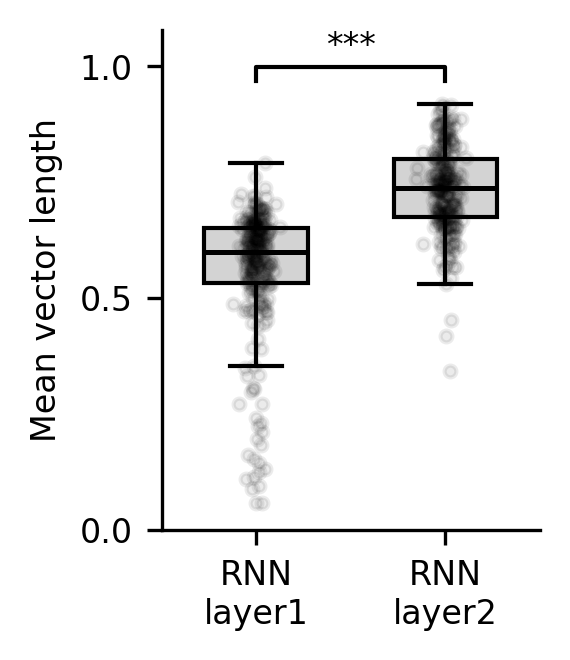

In [9]:
def mean_vector_length(vals, theta):
    vals = np.maximum(vals, 0)
    s = vals.sum()
    if s < 1e-12:
        return np.nan
    x = np.sum(vals * np.cos(theta)) / s
    y = np.sum(vals * np.sin(theta)) / s
    return np.sqrt(x**2 + y**2)

from visualize import compute_ratemaps_lmn_pas_conj_mec

def circular_mean_direction(vals, theta):
    vals = np.maximum(vals, 0)
    s = vals.sum()
    if s < 1e-12:
        return np.nan
    x = np.sum(vals * np.cos(theta)) / s
    y = np.sum(vals * np.sin(theta)) / s
    return np.mod(np.arctan2(y, x), 2 * np.pi)

options.sequence_length = 20
options.batch_size = 100

model.eval()
results = compute_ratemaps_lmn_pas_conj_mec(
    model,
    trajectory_generator,
    options,
    res=60,
    n_avg=100,
    N_lmn=options.Nlmn,
    N_pas=options.Npas,
    N_conj=options.Ncg,
    N_mec=options.Ng,
)

(
    activations_lmn_dir,
    rate_map_lmn_dir,
    activations_pas_dir,
    rate_map_pas_dir,
    activations_conj_dir,
    rate_map_conj_dir,
    activations_mec_dir,
    rate_map_mec_dir,
    activations_lmn_spatial,
    rate_map_lmn_spatial,
    activations_pas_spatial,
    rate_map_pas_spatial,
    activations_conj_spatial,
    rate_map_conj_spatial,
    activations_mec_spatial,
    rate_map_mec_spatial,
    lmn,
    pas,
    conj,
    mec,
    ang,
    pos,
) = results



angles_lmn = np.linspace(0, 2 * np.pi, activations_lmn_dir.shape[1], endpoint=False)
angles_pas = np.linspace(0, 2 * np.pi, activations_pas_dir.shape[1], endpoint=False)

mvl_lmn = np.array([mean_vector_length(a, angles_lmn) for a in activations_lmn_dir])
mvl_pas = np.array([mean_vector_length(a, angles_pas) for a in activations_pas_dir])

mean_lmn = np.nanmean(mvl_lmn)
mean_pas = np.nanmean(mvl_pas)

sem_lmn = np.nanstd(mvl_lmn) / np.sqrt(np.sum(~np.isnan(mvl_lmn)))
sem_pas = np.nanstd(mvl_pas) / np.sqrt(np.sum(~np.isnan(mvl_pas)))

# choose a stats test
lmn_clean = mvl_lmn[~np.isnan(mvl_lmn)]
pas_clean = mvl_pas[~np.isnan(mvl_pas)]

def median_iqr(x):
    return np.nanmedian(x), np.nanpercentile(x, 25), np.nanpercentile(x, 75)

lmn_med, lmn_q1, lmn_q3 = median_iqr(lmn_clean)
pas_med, pas_q1, pas_q3 = median_iqr(pas_clean)

mw = stats.mannwhitneyu(
    lmn_clean,
    pas_clean,
    alternative='two-sided'
)


print(f"LMN: median = {lmn_med:.3g}, IQR = [{lmn_q1:.3g}, {lmn_q3:.3g}], n = {len(lmn_clean)}")
print(f"PaS: median = {pas_med:.3g}, IQR = [{pas_q1:.3g}, {pas_q3:.3g}], n = {len(pas_clean)}")
print(f"Mann-Whitney U = {mw.statistic:.3g}, p = {mw.pvalue:.3g}")
pval = mw.pvalue



def p_to_stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'n.s.'

fig, ax = plt.subplots(figsize=(2, 2.3), dpi=300)

x = [0, 1]
data = [lmn_clean, pas_clean]

bp = ax.boxplot(
    data,
    positions=x,
    widths=0.55,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color='black', linewidth=1.2),
    boxprops=dict(facecolor='lightgrey', edgecolor='black', linewidth=1),
    whiskerprops=dict(color='black', linewidth=1),
    capprops=dict(color='black', linewidth=1),
)

# scatter all cells with a bit of jitter
rng = np.random.default_rng(0)
jitter_lmn = rng.normal(0, 0.04, size=len(lmn_clean))
jitter_pas = rng.normal(0, 0.04, size=len(pas_clean))

ax.scatter(
    np.full(len(lmn_clean), x[0]) + jitter_lmn,
    lmn_clean,
    s=8,
    color='black',
    alpha=0.08,
    zorder=3,
)
ax.scatter(
    np.full(len(pas_clean), x[1]) + jitter_pas,
    pas_clean,
    s=8,
    color='black',
    alpha=0.08,
    zorder=3,
)

# significance bar
y_max = max(np.nanmax(lmn_clean), np.nanmax(pas_clean))
y = y_max + 0.05
h = 0.03
ax.plot([x[0], x[0], x[1], x[1]], [y, y+h, y+h, y], color='black', linewidth=1)
ax.text(np.mean(x), y+h+0.01, p_to_stars(pval), ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(['RNN\nlayer1', 'RNN\nlayer2'], fontsize=8)
ax.set_yticks([0, 0.5, 1.0])
ax.set_ylabel('Mean vector length', fontsize=8)
ax.set_ylim(0, min(1.1, y + h + 0.08))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='y', labelsize=8)

plt.tight_layout()

print(f'p = {pval:.3e}')

plt.savefig('./docs/MVL_Layer1vsLayer2.pdf', dpi=300)


### Section 5: Disstribution of grid score and mean vector length in mEC RNN

In [10]:
from scipy.ndimage import gaussian_filter1d
from visualize import compute_ratemaps_lmn_pas_conj_mec
from scores import GridScorer
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

def compute_hd_tuning(x, ang, n_bins=60, smooth_sigma=None):
    edges = np.linspace(-np.pi, np.pi, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    bin_idx = np.digitize(ang, edges) - 1
    bin_idx = np.clip(bin_idx, 0, n_bins - 1)

    tuning = np.zeros((x.shape[1], n_bins), dtype=np.float32)
    for b in range(n_bins):
        m = bin_idx == b
        if m.any():
            tuning[:, b] = x[m].mean(axis=0)

    if smooth_sigma is not None and smooth_sigma > 0:
        tuning = gaussian_filter1d(
            tuning,
            sigma=float(smooth_sigma),
            axis=1,
            mode='wrap',
        )

    return tuning, centers

def mean_vector_length(tuning, centers):
    tuning = np.maximum(tuning, 0)
    s = tuning.sum(axis=1)

    mvl = np.full(tuning.shape[0], np.nan)
    ok = s > 1e-12

    x = np.sum(tuning[ok] * np.cos(centers)[None, :], axis=1) / s[ok]
    y = np.sum(tuning[ok] * np.sin(centers)[None, :], axis=1) / s[ok]
    mvl[ok] = np.sqrt(x**2 + y**2)
    return mvl

def plot_grid_score_vs_directional_mvl(
    layer_name,
    activations_spatial,
    rate_map_spatial,
    trace,
    ang,
    options,
    output_path,
    grid_threshold=0.3,
    mvl_threshold=0.3,
    n_bins=60,
    smooth_sigma=1.0,
):
    thr = 1e-8
    keep_spatial = np.max(np.abs(activations_spatial), axis=(1, 2)) > thr
    keep_trace = np.max(np.abs(trace), axis=0) > thr
    keep = keep_spatial & keep_trace

    rm_ns = rate_map_spatial[keep]
    trace_ns = trace[:, keep]

    print(f"non-silent {layer_name} cells: {trace_ns.shape[1]}/{trace.shape[1]}")

    res_pos = activations_spatial.shape[-1]
    starts = [0.2] * 10
    ends = np.linspace(0.4, 1.0, num=10)

    coord_range = (
        (-options.box_width / 2, options.box_width / 2),
        (-options.box_height / 2, options.box_height / 2),
    )

    scorer = GridScorer(res_pos, coord_range, zip(starts, ends.tolist()))

    score_60, score_90, max_60_mask, max_90_mask, sac, max_60_ind = zip(
        *[scorer.get_scores(rm.reshape(res_pos, res_pos)) for rm in tqdm(rm_ns)]
    )

    grid_score = np.asarray(score_60)

    tuning, centers = compute_hd_tuning(
        trace_ns,
        ang,
        n_bins=n_bins,
        smooth_sigma=smooth_sigma,
    )
    directional_mvl = mean_vector_length(tuning, centers)

    fig, ax = plt.subplots(figsize=(2, 2.1), dpi=300)

    ax.scatter(
        grid_score,
        directional_mvl,
        s=12,
        color='black',
        alpha=0.2,
        linewidth=0,
    )

    ax.set_xlabel('Grid score', fontsize=8)
    ax.set_ylabel('Directional MVL', fontsize=8)
    ax.tick_params(axis='both', labelsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.axhline(mvl_threshold, color='red', linestyle='--', linewidth=0.8)
    ax.axvline(grid_threshold, color='red', linestyle='--', linewidth=0.8)

    ax.text(
        0.85, 0.85, 'Conj. GC',
        ha='center',
        va='center',
        transform=ax.transAxes,
        fontsize=6,
        color='#009FB9',
    )
    ax.text(
        0.85, 0.1, 'Pure GC',
        ha='center',
        va='center',
        transform=ax.transAxes,
        fontsize=6,
        color='#F18D00',
    )

    ax.set_ylim([0, 1])
    ax.set_xlim([-0.2, 1.2])
    ax.set_title(layer_name, fontsize=8)

    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    plt.show()

    return grid_score, directional_mvl, keep


In [11]:
options.sequence_length = 50
options.batch_size = 100

model.eval()

results = compute_ratemaps_lmn_pas_conj_mec(
    model,
    trajectory_generator,
    options,
    res=60,
    res_pos=20,
    n_avg=50,
    N_lmn=options.Nlmn,
    N_pas=options.Npas,
    N_conj=options.Ncg,
    N_mec=options.Ng,
)

(
    activations_lmn_dir,
    rate_map_lmn_dir,
    activations_pas_dir,
    rate_map_pas_dir,
    activations_conj_dir,
    rate_map_conj_dir,
    activations_mec_dir,
    rate_map_mec_dir,
    activations_lmn_spatial,
    rate_map_lmn_spatial,
    activations_pas_spatial,
    rate_map_pas_spatial,
    activations_conj_spatial,
    rate_map_conj_spatial,
    activations_mec_spatial,
    rate_map_mec_spatial,
    lmn,
    pas,
    conj,
    mec,
    ang,
    pos,
) = results


non-silent Layer 3 cells: 311/512


100%|██████████| 311/311 [00:01<00:00, 222.01it/s]


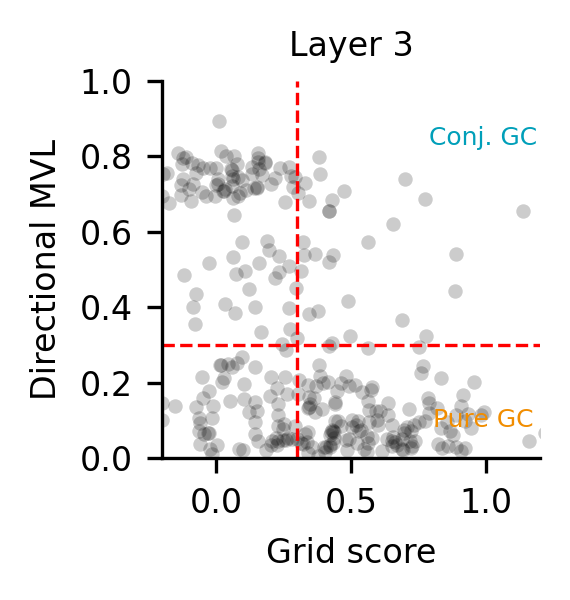

non-silent Layer 4 cells: 460/512


100%|██████████| 460/460 [00:02<00:00, 223.76it/s]


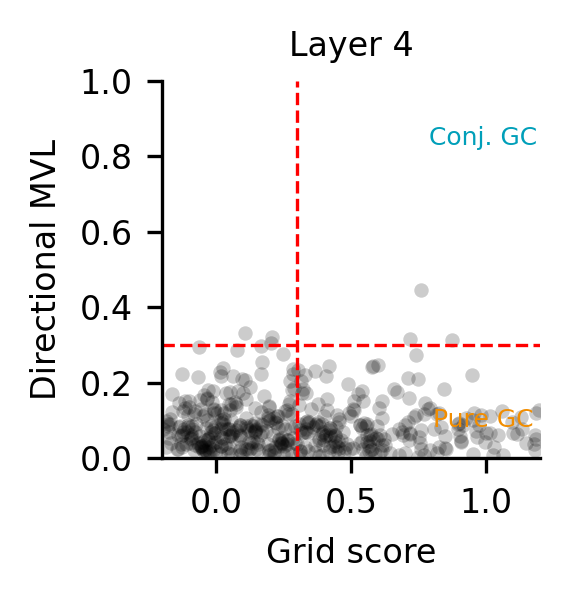

Number of conjunctive grid cells in Layer 3: 29
Fraction among non-silent Layer 3 cells: 29/311
Number of conjunctive grid cells in Layer 4: 3
Fraction among non-silent Layer 4 cells: 3/460
Weakly conjunctive cells in Layer 3: 62/311
Weakly conjunctive cells in Layer 4: 250/460


In [12]:
conj_grid_score, conj_directional_mvl, conj_keep = plot_grid_score_vs_directional_mvl(
    layer_name='Layer 3',
    activations_spatial=activations_conj_spatial,
    rate_map_spatial=rate_map_conj_spatial,
    trace=conj,
    ang=ang,
    options=options,
    output_path='./docs/grid_score_vs_MVL_layer3.pdf',
)

mec_grid_score, mec_directional_mvl, mec_keep = plot_grid_score_vs_directional_mvl(
    layer_name='Layer 4',
    activations_spatial=activations_mec_spatial,
    rate_map_spatial=rate_map_mec_spatial,
    trace=mec,
    ang=ang,
    options=options,
    output_path='./docs/grid_score_vs_MVL_layer4.pdf',
)


grid_threshold = 0.3
mvl_threshold = 0.3

conjunctive_mask = (conj_grid_score > grid_threshold) & (conj_directional_mvl > mvl_threshold)
n_conjunctive = np.sum(conjunctive_mask)

print(f"Number of conjunctive grid cells in Layer 3: {n_conjunctive}")
print(f"Fraction among non-silent Layer 3 cells: {n_conjunctive}/{len(conj_grid_score)}")

#conjunctive grid cells in layer 4
conjunctive_mask_mec = (mec_grid_score > grid_threshold) & (mec_directional_mvl > mvl_threshold)
n_conjunctive_mec = np.sum(conjunctive_mask_mec)
print(f"Number of conjunctive grid cells in Layer 4: {n_conjunctive_mec}")
print(f"Fraction among non-silent Layer 4 cells: {n_conjunctive_mec}/{len(mec_grid_score)}")

#pring weak grid tuning and the same time weak directional tuning in layer 3, which may correspond to the "weakly conjunctive" cells in the experimental literature
weak_conj_mask = (conj_grid_score <= grid_threshold) & (conj_directional_mvl <= mvl_threshold)
print(f"Weakly conjunctive cells in Layer 3: {weak_conj_mask.sum()}/{len(conj_grid_score)}")


#layer 4
weak_conj_mask_mec = (mec_grid_score <= grid_threshold) & (mec_directional_mvl <= mvl_threshold)
print(f"Weakly conjunctive cells in Layer 4: {weak_conj_mask_mec.sum()}/{len(mec_grid_score)}")
 




#### SI figure: Plot grid cells on the grid by MVL map

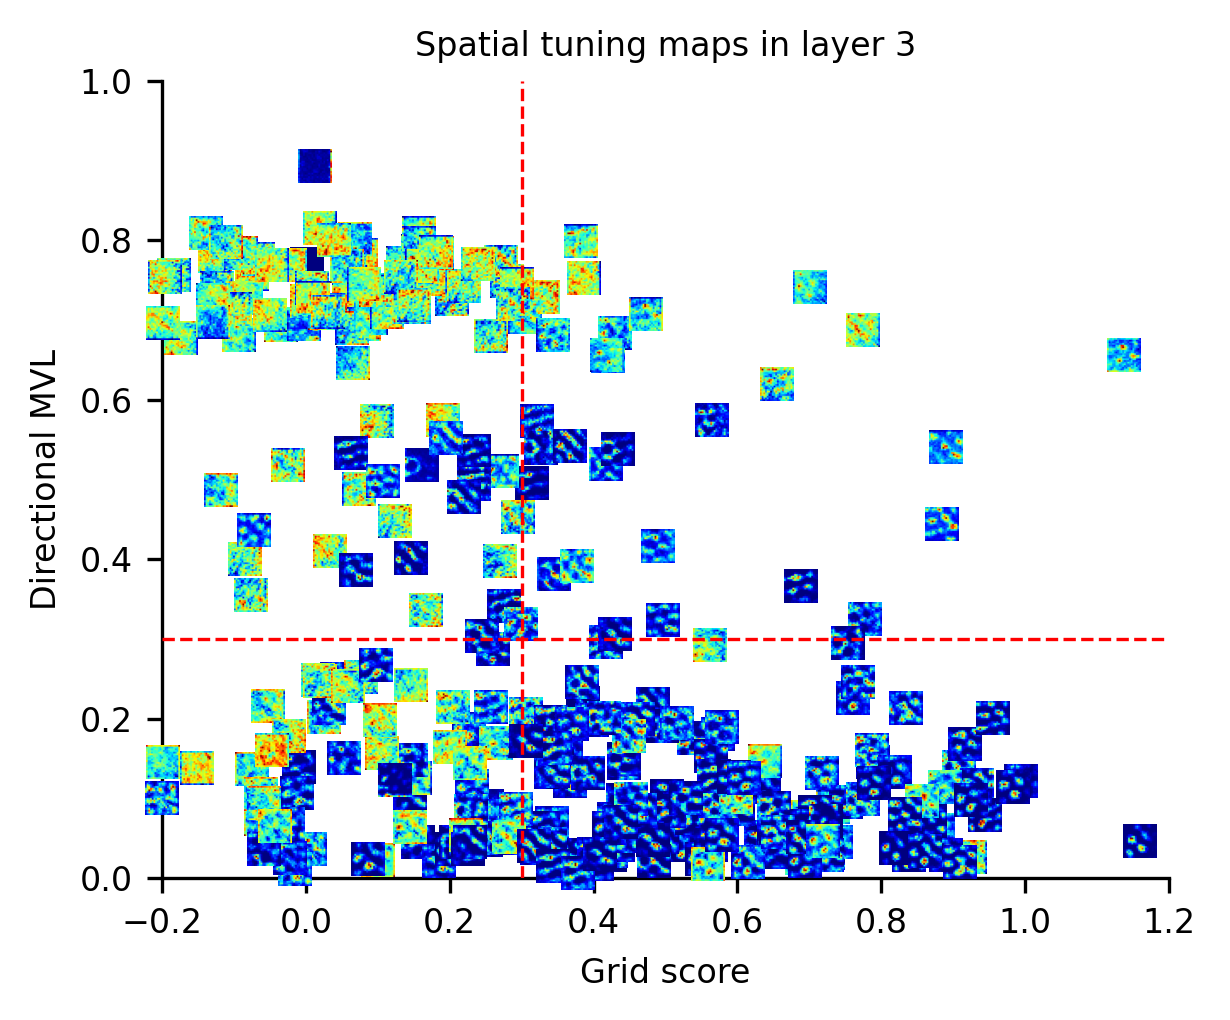

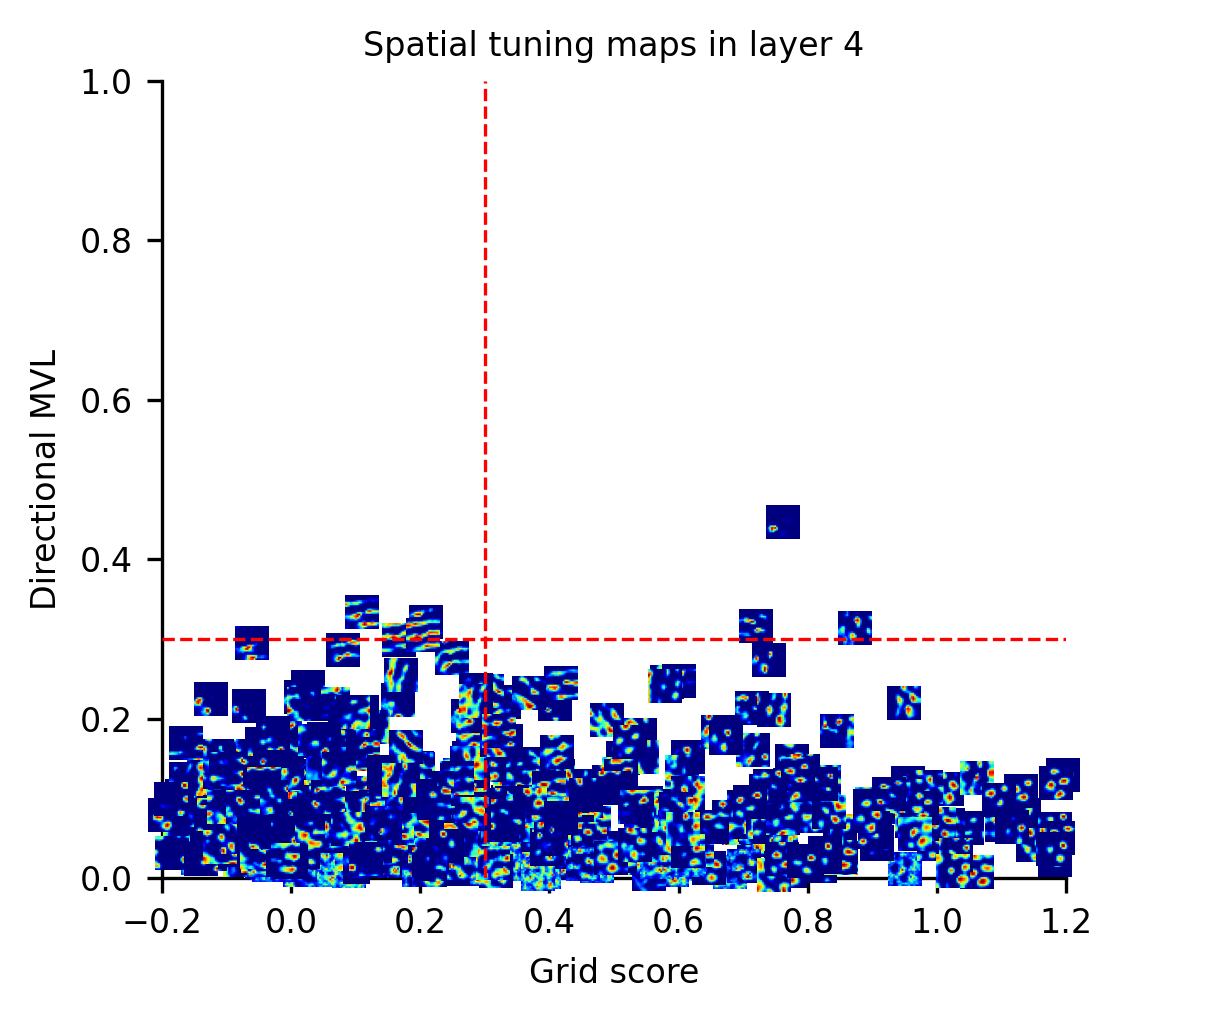

In [13]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox


def normalize_map(x):
    x = np.asarray(x, dtype=float)
    x = x - np.nanmin(x)
    x = x / (np.nanmax(x) + 1e-8)
    return x


def map_to_rgba(gmap, cmap="jet"):
    cmap_obj = plt.get_cmap(cmap)
    gmap = normalize_map(gmap)
    rgba = cmap_obj(gmap)
    return rgba


def plot_map_scatter(
    grid_score,
    directional_mvl,
    orig_ids,
    rate_map_spatial,
    activations_spatial,
    layer_name="Layer",
    use_rate_map=True,
    cmap="jet",
    zoom=0.45,
    figsize=(8, 6),
    dpi=300,
    xlim=(-0.2, 1.2),
    ylim=(0, 1.0),
    grid_thr=0.3,
    mvl_thr=0.3,
    save_path=None,
):
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    ax.set_xlabel("Grid score", fontsize=8)
    ax.set_ylabel("Directional MVL", fontsize=8)
    ax.tick_params(axis="both", labelsize=8)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.axhline(mvl_thr, color="red", linestyle="--", linewidth=0.8, zorder=5)
    ax.axvline(grid_thr, color="red", linestyle="--", linewidth=0.8, zorder=5)
    ax.set_title(layer_name, fontsize=8)

    # faint reference points
    ax.scatter(
        grid_score,
        directional_mvl,
        s=4,
        color="lightgray",
        alpha=0.25,
        linewidth=0,
        zorder=1,
    )

    res_pos = activations_spatial.shape[-1]

    for i, cell_id in enumerate(orig_ids):
        x = grid_score[i]
        y = directional_mvl[i]

        if np.isnan(x) or np.isnan(y):
            continue

        if use_rate_map:
            gmap = rate_map_spatial[cell_id].reshape(res_pos, res_pos)
        else:
            gmap = activations_spatial[cell_id]

        rgba = map_to_rgba(gmap, cmap=cmap)
        imagebox = OffsetImage(rgba, zoom=zoom)
        ab = AnnotationBbox(
            imagebox,
            (x, y),
            frameon=False,
            pad=0.0,
            box_alignment=(0.5, 0.5),
            zorder=3,
        )
        ax.add_artist(ab)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight", pad_inches=0.03)

    plt.show()
    
    

act_conj_ns = activations_conj_spatial[conj_keep]
rm_conj_ns = rate_map_conj_spatial[conj_keep]
conj_ns = conj[:, conj_keep]
conj_orig_ids = np.where(conj_keep)[0]

conj_direction_tuning, conj_centers = compute_hd_tuning(
    conj_ns,
    ang,
    n_bins=60,
    smooth_sigma=1.0,
)

act_mec_ns = activations_mec_spatial[mec_keep]
rm_mec_ns = rate_map_mec_spatial[mec_keep]
mec_ns = mec[:, mec_keep]
mec_orig_ids = np.where(mec_keep)[0]    

mec_direction_tuning, mec_centers = compute_hd_tuning(
    mec_ns,
    ang,
    n_bins=60,
    smooth_sigma=1.0,
)

plot_map_scatter(
    grid_score=conj_grid_score,
    directional_mvl=conj_directional_mvl,
    orig_ids=conj_orig_ids,
    rate_map_spatial=rate_map_conj_spatial,
    activations_spatial=activations_conj_spatial,
    layer_name="Spatial tuning maps in layer 3",
    use_rate_map=True,
    cmap="jet",
    zoom=0.4,
    figsize=(4.2, 3.5),
    dpi=300,
    xlim=(-0.2, 1.2),
    ylim=(0, 1.0),
    grid_thr=0.3,
    mvl_thr=0.3,
    save_path="./docs/grid_score_vs_MVL_maps_layer3.pdf",
)


plot_map_scatter(
    grid_score=mec_grid_score,
    directional_mvl=mec_directional_mvl,
    orig_ids=mec_orig_ids,
    rate_map_spatial=rate_map_mec_spatial,
    activations_spatial=activations_mec_spatial,
    layer_name="Spatial tuning maps in layer 4",
    use_rate_map=True,
    cmap="jet",
    zoom=0.4,
    figsize=(4.2, 3.5),
    dpi=300,
    xlim=(-0.2, 1.2),
    ylim=(0, 1.0),
    grid_thr=0.3,
    mvl_thr=0.3,
    save_path="./docs/grid_score_vs_MVL_maps_layer4.pdf",
)


#### SI figure: Plot directional maps of cells on the grid by MVL map

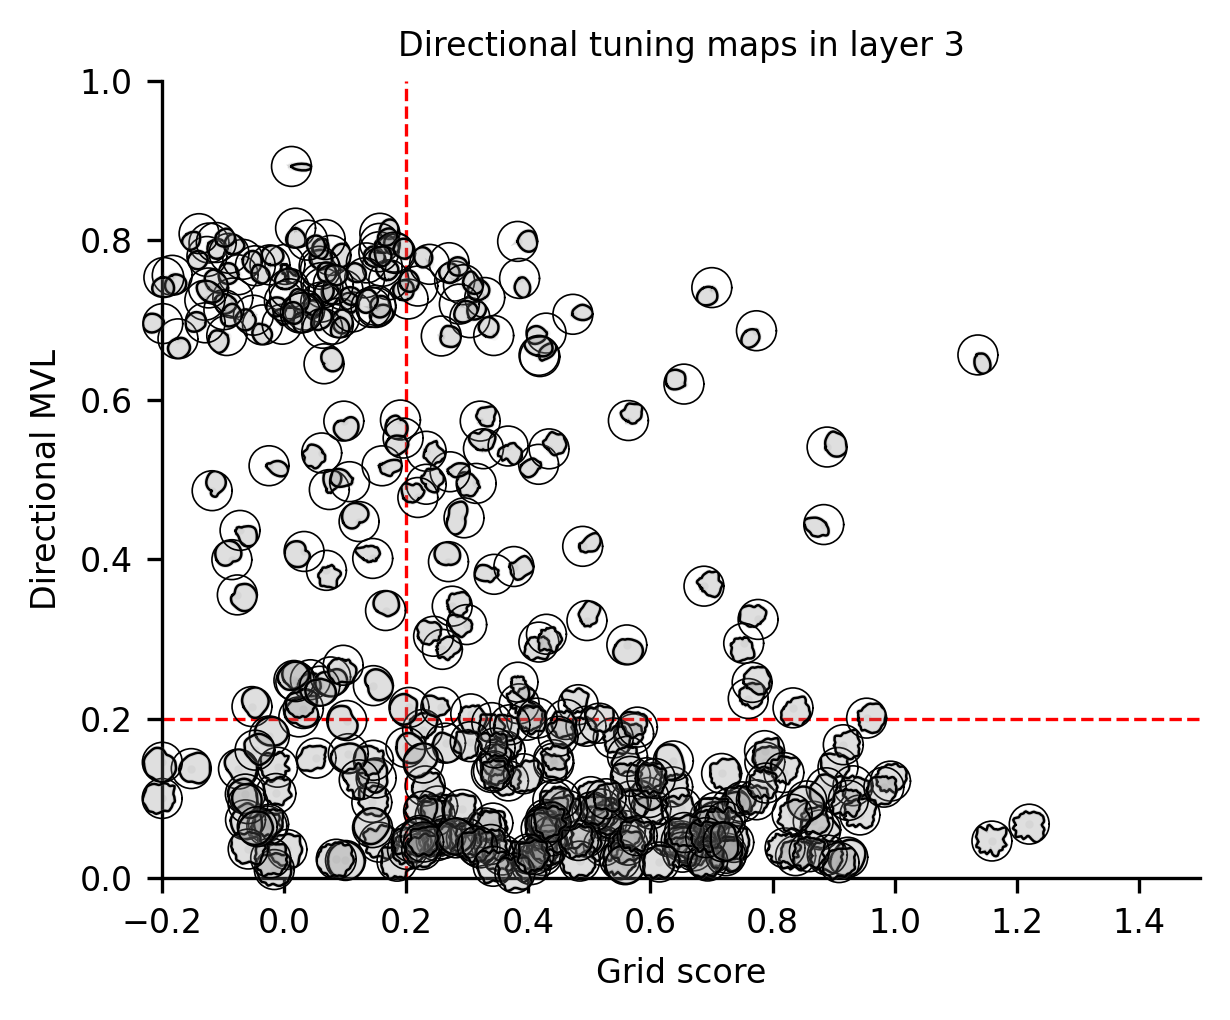

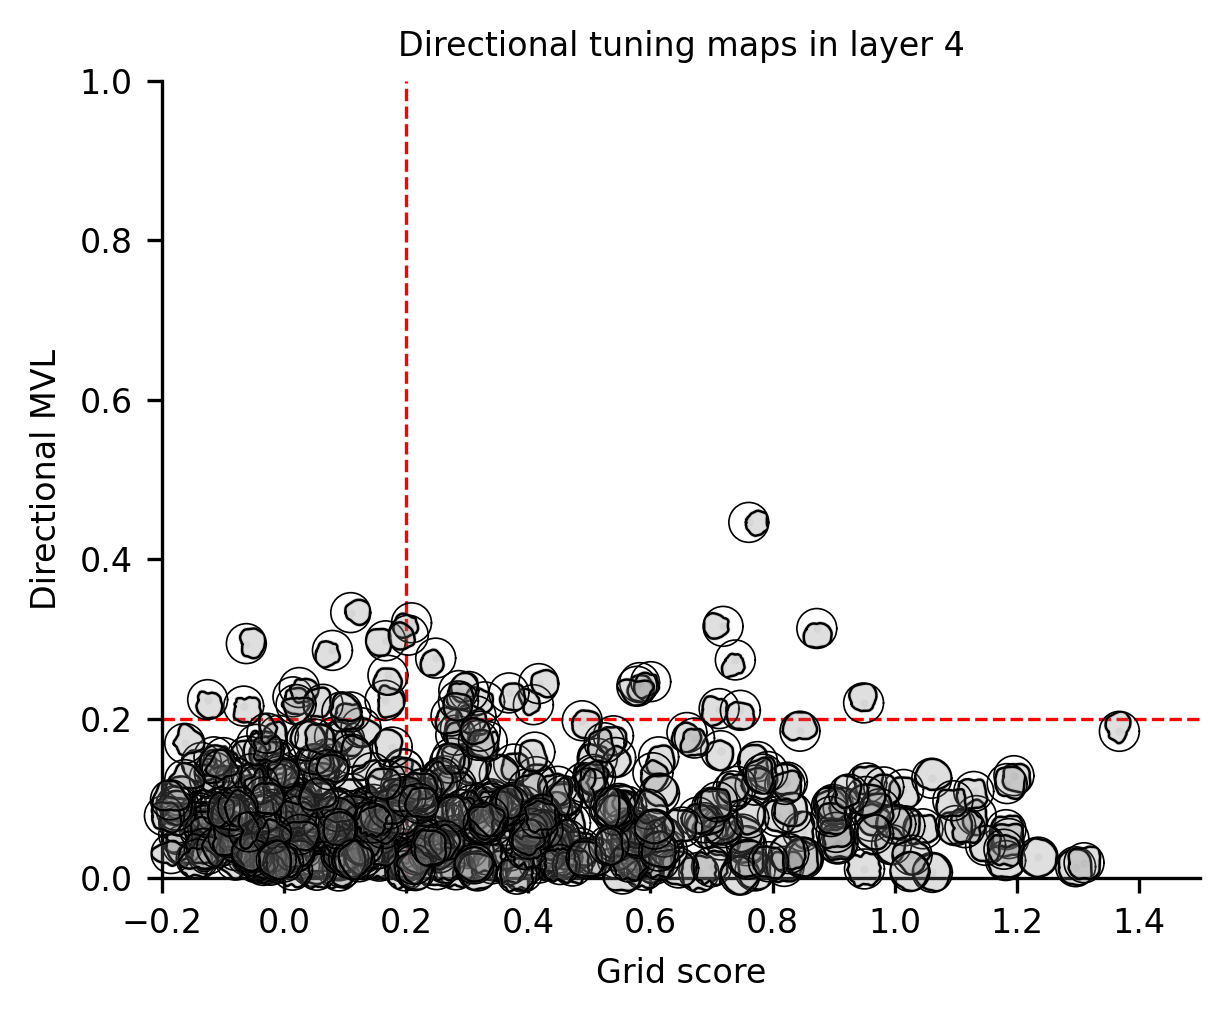

In [14]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib import cm


def normalize_1d(x):
    x = np.asarray(x, dtype=float)
    x = x - np.nanmin(x)
    x = x / (np.nanmax(x) + 1e-8)
    return x


def direction_tuning_to_rgba(vals, cmap="jet", height=18):
    vals = normalize_1d(vals)
    cmap_obj = plt.get_cmap(cmap)

    rgba_1d = cmap_obj(vals)          # [n_bins, 4]
    rgba_img = np.tile(rgba_1d[None, :, :], (height, 1, 1))  # [H, n_bins, 4]
    return rgba_img


def plot_polar_direction_map_scatter(
    grid_score,
    directional_mvl,
    tuning_curves,
    centers,
    layer_name="RNN layer 3",
    figsize=(8, 8),
    dpi=300,
    xlim=(-0.2, 1.2),
    ylim=(0, 1.0),
    grid_thr=0.2,
    mvl_thr=0.2,
    inset_size=0.045,
    save_path=None,
):
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    ax.set_xlabel("Grid score", fontsize=8)
    ax.set_ylabel("Directional MVL", fontsize=8)
    ax.tick_params(axis="both", labelsize=8)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.axhline(mvl_thr, color="red", linestyle="--", linewidth=0.8)
    ax.axvline(grid_thr, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(layer_name, fontsize=8)

    # faint reference points
    ax.scatter(
        grid_score,
        directional_mvl,
        s=4,
        color="lightgray",
        alpha=0.25,
        linewidth=0,
        zorder=1,
    )

    theta = np.concatenate([centers, centers[:1]])

    for i in range(len(grid_score)):
        x = grid_score[i]
        y = directional_mvl[i]

        if np.isnan(x) or np.isnan(y):
            continue

        vals = tuning_curves[i].copy()
        vals = np.maximum(vals, 0)

        if np.nanmax(vals) <= 1e-12:
            continue

        vals = vals / (np.nanmax(vals) + 1e-8)
        vals = np.concatenate([vals, vals[:1]])

        # data coords -> axes fraction
        x_ax = (x - xlim[0]) / (xlim[1] - xlim[0])
        y_ax = (y - ylim[0]) / (ylim[1] - ylim[0])

        # skip anything outside visible area
        if not (0 <= x_ax <= 1 and 0 <= y_ax <= 1):
            continue

        inset = ax.inset_axes(
            [x_ax - inset_size / 2, y_ax - inset_size / 2, inset_size, inset_size],
            transform=ax.transAxes,
            projection="polar",
        )

        inset.plot(theta, vals, color="black", linewidth=0.6)
        inset.fill(theta, vals, color="gray", alpha=0.25)
        inset.set_ylim(0, 1.0)
        inset.set_xticks([])
        inset.set_yticks([])
        inset.spines["polar"].set_linewidth(0.4)
        inset.spines["polar"].set_color("black")
        inset.set_facecolor("none")

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight", pad_inches=0.03)

    plt.show()

plot_polar_direction_map_scatter(
    grid_score=conj_grid_score,
    directional_mvl=conj_directional_mvl,
    tuning_curves=conj_direction_tuning,
    centers=conj_centers,
    layer_name="Directional tuning maps in layer 3",
    figsize=(4.2, 3.5),
    dpi=300,
    xlim=(-0.2, 1.5),
    ylim=(0, 1.0),
    grid_thr=0.2,
    mvl_thr=0.2,
    inset_size=0.05,
    save_path="./docs/grid_score_vs_MVL_polarmaps_layer3.pdf",
)


plot_polar_direction_map_scatter(
    grid_score=mec_grid_score,
    directional_mvl=mec_directional_mvl,
    tuning_curves=mec_direction_tuning,
    centers=mec_centers,
    layer_name="Directional tuning maps in layer 4",
    figsize=(4.2, 3.5),
    dpi=300,
    xlim=(-0.2, 1.5),
    ylim=(0, 1.0),
    grid_thr=0.2,
    mvl_thr=0.2,
    inset_size=0.05,
    save_path="./docs/grid_score_vs_MVL_polarmaps_layer4.pdf",
)


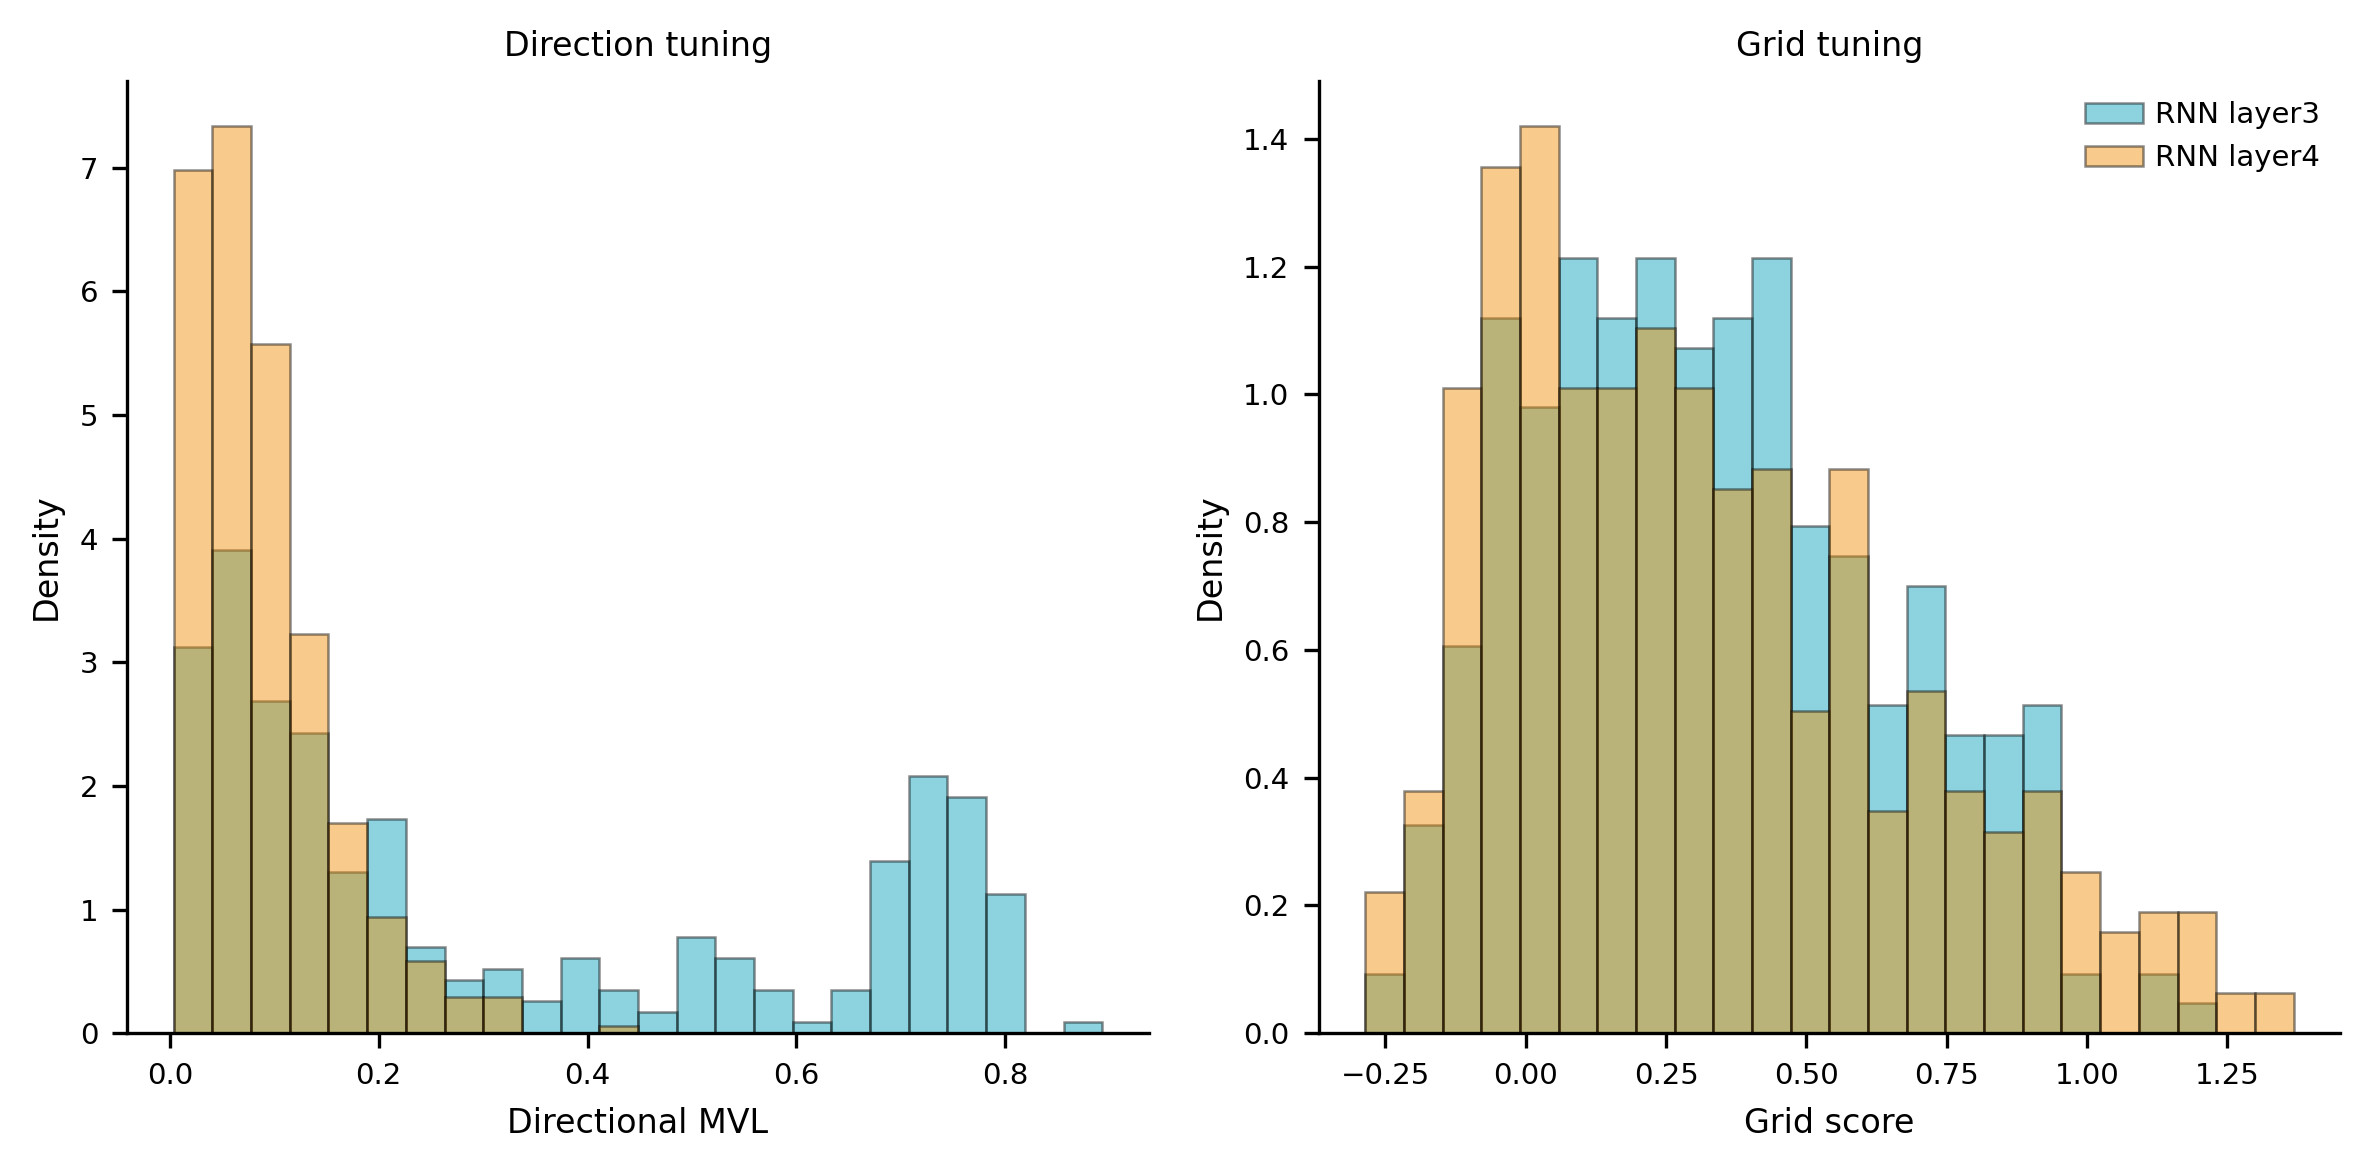

In [15]:
# Compare distributions instead of thresholded percentages
n_total = 512

fig, axes = plt.subplots(1, 2, figsize=(8, 4.0), dpi=300)

# Colors
color_conj = "#009FB9"
color_mec = "#F18D00"

# -------------------------
# Left panel: directional MVL
# -------------------------
bins_mvl = np.linspace(
    min(conj_directional_mvl.min(), mec_directional_mvl.min()),
    max(conj_directional_mvl.max(), mec_directional_mvl.max()),
    25,
)

axes[0].hist(
    conj_directional_mvl,
    bins=bins_mvl,
    density=True,
    alpha=0.45,
    color=color_conj,
    edgecolor="black",
    linewidth=0.6,
    label="RNN layer3",
)

axes[0].hist(
    mec_directional_mvl,
    bins=bins_mvl,
    density=True,
    alpha=0.45,
    color=color_mec,
    edgecolor="black",
    linewidth=0.6,
    label="RNN layer4",
)

axes[0].set_xlabel("Directional MVL", fontsize=8)
axes[0].set_ylabel("Density", fontsize=8)
axes[0].tick_params(axis="both", labelsize=7)
axes[0].set_title("Direction tuning", fontsize=8)

# -------------------------
# Right panel: grid score
# -------------------------
bins_grid = np.linspace(
    min(conj_grid_score.min(), mec_grid_score.min()),
    max(conj_grid_score.max(), mec_grid_score.max()),
    25,
)

axes[1].hist(
    conj_grid_score,
    bins=bins_grid,
    density=True,
    alpha=0.45,
    color=color_conj,
    edgecolor="black",
    linewidth=0.6,
    label="RNN layer3",
)

axes[1].hist(
    mec_grid_score,
    bins=bins_grid,
    density=True,
    alpha=0.45,
    color=color_mec,
    edgecolor="black",
    linewidth=0.6,
    label="RNN layer4",
)

axes[1].set_xlabel("Grid score", fontsize=8)
axes[1].set_ylabel("Density", fontsize=8)
axes[1].tick_params(axis="both", labelsize=7)
axes[1].set_title("Grid tuning", fontsize=8)

# Shared styling
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[1].legend(
    frameon=False,
    fontsize=7,
    loc="upper right",
    handletextpad=0.4,
    borderpad=0.2,
)

plt.tight_layout()

plt.savefig(
    "./docs/conj_mec_mvl_grid_histograms.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


### plot example pure and conj grid cells

In [16]:
from matplotlib.gridspec import GridSpec

def pick_top_cells(mask, sort_score, n=9):
    ids = np.where(mask)[0]
    if len(ids) == 0:
        return ids

    order = np.argsort(-sort_score[ids])
    return ids[order[:min(n, len(ids))]]

def plot_grid_and_direction_examples(
    local_ids,
    title,
    save_path,
    grid_score,
    directional_mvl,
    activations_spatial_ns,
    hd_tuning,
    centers,
    orig_ids,
    cells_per_row=3,
):
    n_show = len(local_ids)
    if n_show == 0:
        print(f"No cells found for {title}")
        return

    n_cell_rows = int(np.ceil(n_show / cells_per_row))

    fig = plt.figure(figsize=(4.3, 2.2), dpi=300)
    gs = GridSpec(
        n_cell_rows,
        cells_per_row * 2,
        figure=fig,
        width_ratios=[1, 1] * cells_per_row,
        hspace=0.2,
        wspace=0.15,
    )

    theta = np.concatenate([centers, centers[:1]])

    for i, local_id in enumerate(local_ids):
        cell_row = i // cells_per_row
        cell_col = i % cells_per_row

        map_col = cell_col * 2
        pol_col = cell_col * 2 + 1

        original_id = orig_ids[local_id]

        ax_map = fig.add_subplot(gs[cell_row, map_col])
        ax_map.imshow(activations_spatial_ns[local_id], cmap='jet', origin='lower')
        ax_map.set_xticks([])
        ax_map.set_yticks([])
        # ax_map.set_title(
        #     f"{original_id}\nG={grid_score[local_id]:.2f}",
        #     fontsize=5,
        #     pad=1,
        # )

        ax_pol = fig.add_subplot(gs[cell_row, pol_col], projection='polar')
        vals = hd_tuning[local_id].copy()
        vals = np.maximum(vals, 0)
        vals = vals / (vals.max() + 1e-8)
        vals = np.concatenate([vals, vals[:1]])

        ax_pol.plot(theta, vals, color='black', linewidth=0.8)
        ax_pol.fill(theta, vals, color='gray', alpha=0.25)
        ax_pol.set_ylim(0, 1.05)
        ax_pol.set_xticks([])
        ax_pol.set_yticks([])
        # ax_pol.set_title(
        #     f"MVL={directional_mvl[local_id]:.2f}",
        #     fontsize=5,
        #     pad=1,
        # )

    for i in range(n_show, n_cell_rows * cells_per_row):
        cell_row = i // cells_per_row
        cell_col = i % cells_per_row

        ax_map = fig.add_subplot(gs[cell_row, cell_col * 2])
        ax_pol = fig.add_subplot(gs[cell_row, cell_col * 2 + 1], projection='polar')
        ax_map.axis('off')
        ax_pol.axis('off')

    fig.suptitle(title, fontsize=8, y=1.02)
    plt.tight_layout()

    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


In [17]:
grid_thr = 0.3
dir_thr = 0.3
n_pick = 9

# Layer 3: Conjunctive grid cells in Conj layer
conj_layer_conjunctive_mask = (
    (conj_grid_score > grid_thr) &
    (conj_directional_mvl > dir_thr)
)

conj_layer_conjunctive_sort_score = (
    5*conj_grid_score + conj_directional_mvl
)

conj_layer_conjunctive_ids = pick_top_cells(
    conj_layer_conjunctive_mask,
    conj_layer_conjunctive_sort_score,
    n=n_pick,
)

# Layer 4: Pure grid cells in mEC
mec_layer_pure_grid_mask = (
    (mec_grid_score > grid_thr) &
    (mec_directional_mvl <= dir_thr)
)

mec_layer_pure_grid_sort_score = (
    5*mec_grid_score + (1 - mec_directional_mvl)
)

mec_layer_pure_grid_ids = pick_top_cells(
    mec_layer_pure_grid_mask,
    mec_layer_pure_grid_sort_score,
    n=n_pick,
)

print(f"Conj layer conjunctive GC candidates: {np.sum(conj_layer_conjunctive_mask)}")
print(f"mEC layer pure GC candidates: {np.sum(mec_layer_pure_grid_mask)}")

print("Conj layer conjunctive GC selected local ids:", conj_layer_conjunctive_ids)
print("mEC layer pure GC selected local ids:", mec_layer_pure_grid_ids)


Conj layer conjunctive GC candidates: 29
mEC layer pure GC candidates: 204
Conj layer conjunctive GC selected local ids: [222 157 215  74 270 147 175 183  98]
mEC layer pure GC selected local ids: [138 378 260 298 173 172 267  84  51]


/tmp/ipykernel_506163/2508325733.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


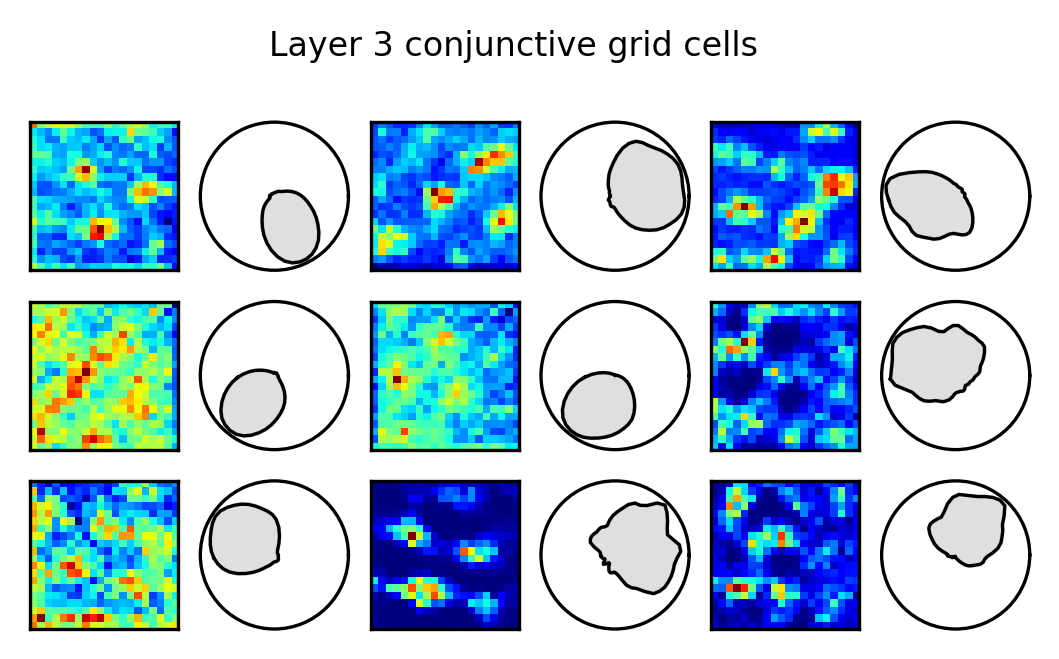

/tmp/ipykernel_506163/2508325733.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


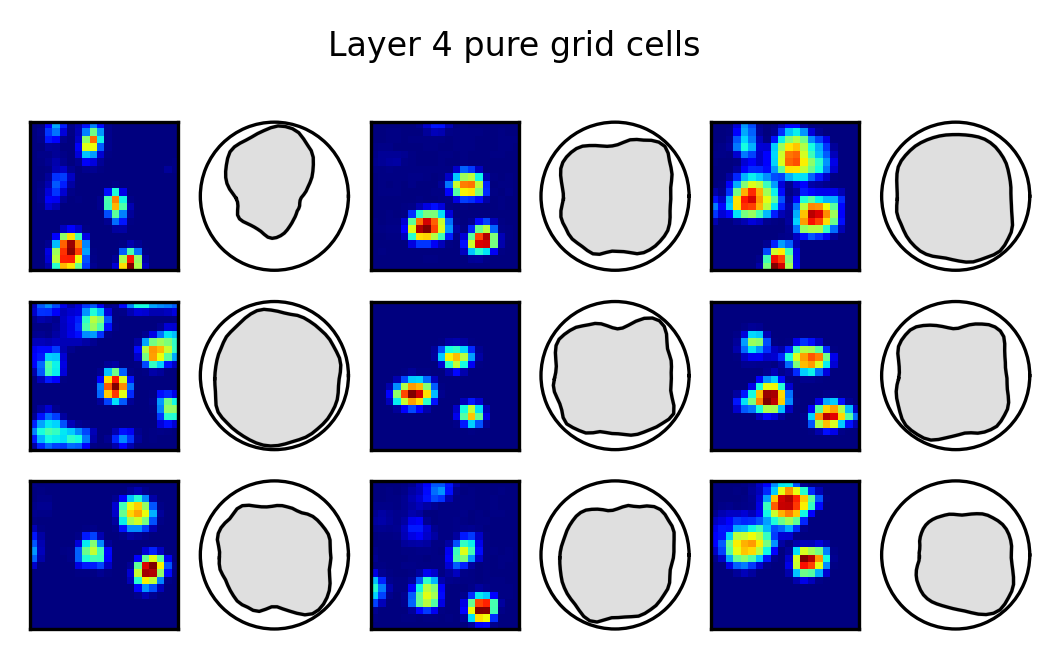

In [18]:

# Reconstruct non-silent layer variables from the keep masks

act_conj_ns = activations_conj_spatial[conj_keep]
rm_conj_ns = rate_map_conj_spatial[conj_keep]
conj_ns = conj[:, conj_keep]
conj_orig_ids = np.where(conj_keep)[0]

conj_tuning, conj_centers = compute_hd_tuning(
    conj_ns,
    ang,
    n_bins=60,
    smooth_sigma=1.0,
)

act_mec_ns = activations_mec_spatial[mec_keep]
rm_mec_ns = rate_map_mec_spatial[mec_keep]
mec_ns = mec[:, mec_keep]
mec_orig_ids = np.where(mec_keep)[0]

mec_tuning, mec_centers = compute_hd_tuning(
    mec_ns,
    ang,
    n_bins=60,
    smooth_sigma=1.0,
)


plot_grid_and_direction_examples(
    conj_layer_conjunctive_ids,
    title='Layer 3 conjunctive grid cells',
    save_path='./docs/layer3_conjunctive_GC_9cells.pdf',
    grid_score=conj_grid_score,
    directional_mvl=conj_directional_mvl,
    activations_spatial_ns=act_conj_ns,
    hd_tuning=conj_tuning,
    centers=conj_centers,
    orig_ids=conj_orig_ids,
    cells_per_row=3,
)

plot_grid_and_direction_examples(
    mec_layer_pure_grid_ids,
    title='Layer 4 pure grid cells',
    save_path='./docs/layer4_pure_GC_9cells.pdf',
    grid_score=mec_grid_score,
    directional_mvl=mec_directional_mvl,
    activations_spatial_ns=act_mec_ns,
    hd_tuning=mec_tuning,
    centers=mec_centers,
    orig_ids=mec_orig_ids,
    cells_per_row=3,
)


### Check speed cells in mEC RNN

In [19]:
from scipy.ndimage import gaussian_filter1d

def compute_speed_tuning_by_layer(
    model,
    trajectory_generator,
    options,
    layer="conj",          # "conj" or "mec"
    n_avg=100,
    n_bins=40,
    smooth_sigma=1.0,
    N_cells=None,
    speed_percentile=(1, 99),
    min_count=50,
):
    if layer not in {"conj", "mec"}:
        raise ValueError("layer must be 'conj' or 'mec'")

    if N_cells is None:
        if layer == "conj":
            N_cells = options.Ncg
        else:
            N_cells = options.Ng

    speed_all = []
    layer_all = []

    model.eval()

    for _ in range(n_avg):
        inputs, _, targets = trajectory_generator.get_test_batch()

        if not (isinstance(inputs, tuple) and len(inputs) == 4):
            raise ValueError(
                "Expected inputs=(speed, init_place_actv, ang_vel, init_dir_actv)."
            )

        speed, init_actp, ang_v, init_dir_actv = inputs

        with torch.no_grad():
            lmn_batch = model.Lmn((ang_v, init_dir_actv))

            pas_out = model.PaS(lmn_batch, init_dir_actv)
            pas_batch = pas_out[0] if isinstance(pas_out, tuple) else pas_out

            conj_batch = model.Conj((speed, init_actp), pas_batch)

            if layer == "conj":
                layer_batch = conj_batch
            else:
                layer_batch = model.mEC((speed, init_actp), conj_batch)

        speed_np = speed.detach().cpu().numpy()
        layer_np = layer_batch.detach().cpu().numpy()

        if speed_np.ndim == 3 and speed_np.shape[-1] == 1:
            speed_np = speed_np.squeeze(-1)

        # speed: [T, B], layer_np: [T, B, N]
        T = min(speed_np.shape[0], layer_np.shape[0])
        B = min(speed_np.shape[1], layer_np.shape[1])

        speed_np = speed_np[:T, :B].reshape(-1)
        layer_np = layer_np[:T, :B, :N_cells].reshape(-1, N_cells)

        speed_all.append(speed_np)
        layer_all.append(layer_np)

    speed_all = np.concatenate(speed_all, axis=0)
    layer_all = np.concatenate(layer_all, axis=0)

    valid = np.isfinite(speed_all)
    speed_all = speed_all[valid]
    layer_all = layer_all[valid]

    lo, hi = np.nanpercentile(speed_all, speed_percentile)
    in_range = (speed_all >= lo) & (speed_all <= hi)

    speed_use = speed_all[in_range]
    layer_use = layer_all[in_range]

    print(
        f"[{layer}] speed range used: {lo:.4f} to {hi:.4f} "
        f"({speed_percentile[0]}-{speed_percentile[1]} percentile), "
        f"samples kept: {len(speed_use)}/{len(speed_all)}"
    )

    thr = 1e-8
    keep = np.max(np.abs(layer_use), axis=0) > thr
    layer_ns = layer_use[:, keep]
    orig_ids = np.where(keep)[0]

    print(f"[{layer}] non-silent cells: {layer_ns.shape[1]}/{layer_use.shape[1]}")

    edges = np.linspace(lo, hi, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    bin_idx = np.digitize(speed_use, edges) - 1
    valid_bin = (bin_idx >= 0) & (bin_idx < n_bins)

    speed_use = speed_use[valid_bin]
    layer_ns = layer_ns[valid_bin]
    bin_idx = bin_idx[valid_bin]

    counts = np.bincount(bin_idx, minlength=n_bins)
    enough_count = counts >= min_count

    tuning = np.full((layer_ns.shape[1], n_bins), np.nan, dtype=np.float32)

    for b in range(n_bins):
        if enough_count[b]:
            tuning[:, b] = layer_ns[bin_idx == b].mean(axis=0)

    print(f"[{layer}] bins with count >= {min_count}: {np.sum(enough_count)}/{n_bins}")
    print(f"[{layer}] bin counts:", counts)

    tuning_for_smooth = tuning.copy()

    for i in range(tuning_for_smooth.shape[0]):
        good = np.isfinite(tuning_for_smooth[i])
        if np.sum(good) >= 2:
            tuning_for_smooth[i, ~good] = np.interp(
                centers[~good],
                centers[good],
                tuning_for_smooth[i, good],
            )
        elif np.sum(good) == 1:
            tuning_for_smooth[i, ~good] = tuning_for_smooth[i, good][0]

    if smooth_sigma is not None and smooth_sigma > 0:
        tuning_for_smooth = gaussian_filter1d(
            tuning_for_smooth,
            sigma=float(smooth_sigma),
            axis=1,
            mode="nearest",
        )
        tuning = tuning_for_smooth
        tuning[:, ~enough_count] = np.nan

    return tuning, centers, orig_ids, speed_use, layer_ns, counts, enough_count


In [20]:
conj_speed_tuning, conj_speed_centers, conj_speed_orig_ids, conj_speed_samples, conj_speed_ns, conj_speed_counts, conj_speed_enough_count = compute_speed_tuning_by_layer(
    model,
    trajectory_generator,
    options,
    layer="conj",
    n_avg=100,
    n_bins=40,
    smooth_sigma=1.0,
    N_cells=options.Ncg,
    speed_percentile=(1, 99),
    min_count=50,
)
mec_speed_tuning, mec_speed_centers, mec_speed_orig_ids, mec_speed_samples, mec_speed_ns, mec_speed_counts, mec_speed_enough_count = compute_speed_tuning_by_layer(
    model,
    trajectory_generator,
    options,
    layer="mec",
    n_avg=100,
    n_bins=40,
    smooth_sigma=1.0,
    N_cells=options.Ng,
    speed_percentile=(1, 99),
    min_count=50,
)


[conj] speed range used: 0.0018 to 0.0493 (1-99 percentile), samples kept: 490000/500000
[conj] non-silent cells: 311/512
[conj] bins with count >= 50: 40/40
[conj] bin counts: [ 8119 11277 13653 15046 16176 17340 18026 19043 19647 20264 20810 20701
 20910 20705 20461 20068 19190 18278 17460 16573 15610 14424 13393 12139
 11060  9887  8728  7881  7162  6177  5352  4707  4113  3447  2994  2511
  2094  1868  1482  1224]
[mec] speed range used: 0.0018 to 0.0492 (1-99 percentile), samples kept: 490000/500000
[mec] non-silent cells: 460/512
[mec] bins with count >= 50: 40/40
[mec] bin counts: [ 8272 11385 13867 15145 16340 17265 18045 18979 19453 20107 20457 20917
 20903 20993 20533 19901 19335 18488 17376 16512 15400 14385 13270 12101
 10878  9912  8991  7821  7008  6129  5456  4720  4038  3474  2965  2467
  2124  1785  1567  1236]


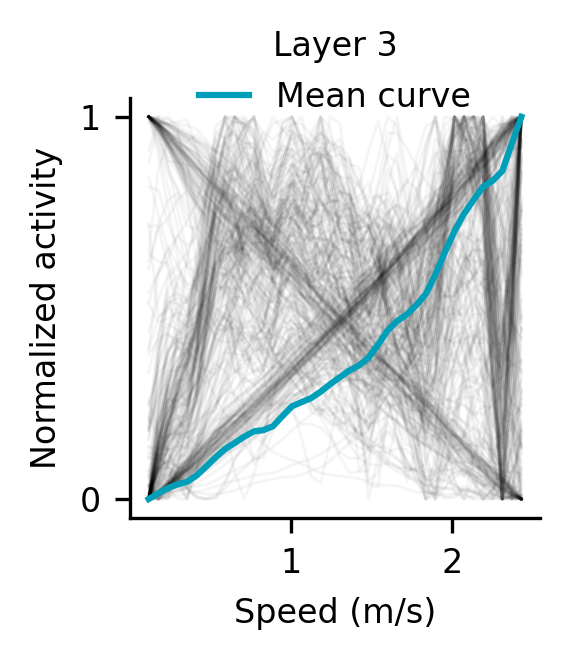

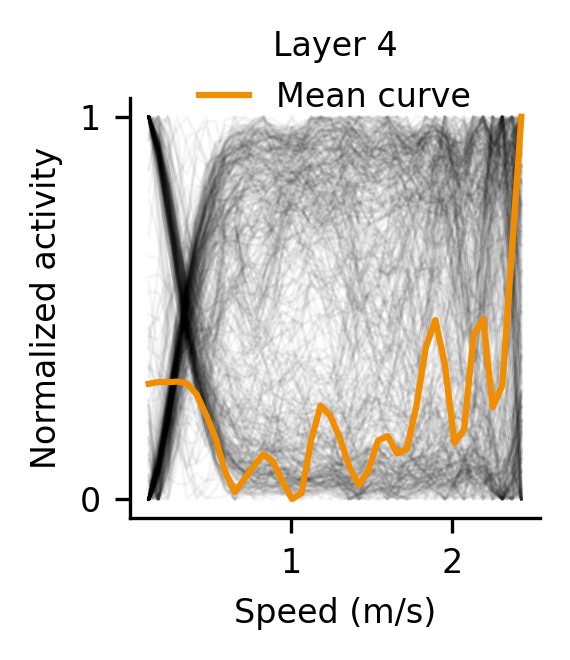

In [21]:
dt = 0.02

def plot_speed_tuning_all_cells(
    tuning,
    speed_centers,
    enough_count=None,
    mean_color="#009FB9",
    save_path=None,
    title=None,
):
    speed_centers_mps = speed_centers / dt

    fig, ax = plt.subplots(figsize=(2, 2.3), dpi=300)

    for i in range(tuning.shape[0]):
        vals = tuning[i].copy()
        good = np.isfinite(vals)

        if np.sum(good) < 2:
            continue

        vals_norm = vals.copy()
        vals_norm[good] = vals_norm[good] - np.nanmin(vals_norm[good])
        vals_norm[good] = vals_norm[good] / (np.nanmax(vals_norm[good]) + 1e-8)

        ax.plot(
            speed_centers_mps[good],
            vals_norm[good],
            color="black",
            alpha=0.04,
            linewidth=0.7,
        )

    mean_tuning = np.nanmean(tuning, axis=0)
    good_mean = np.isfinite(mean_tuning)

    mean_tuning_norm = mean_tuning.copy()
    mean_tuning_norm[good_mean] = mean_tuning_norm[good_mean] - np.nanmin(mean_tuning_norm[good_mean])
    mean_tuning_norm[good_mean] = mean_tuning_norm[good_mean] / (np.nanmax(mean_tuning_norm[good_mean]) + 1e-8)

    ax.plot(
        speed_centers_mps[good_mean],
        mean_tuning_norm[good_mean],
        color=mean_color,
        linewidth=1.5,
        label="Mean curve",
    )

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 0.93),
        frameon=False,
        fontsize=8,
        handlelength=1.5,
        borderaxespad=0,
    )

    if enough_count is not None:
        bad = ~enough_count
        ax.scatter(
            speed_centers_mps[bad],
            np.full(np.sum(bad), -0.03),
            marker="x",
            s=8,
            color="red",
            linewidth=0.6,
            clip_on=False,
        )

    ax.set_xlabel("Speed (m/s)", fontsize=8)
    ax.set_ylabel("Normalized activity", fontsize=8)
    ax.set_yticks([0, 1])
    ax.tick_params(axis="both", labelsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(-0.05, 1.05)

    if title is not None:
        ax.set_title(title, fontsize=8, pad=10)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    
plot_speed_tuning_all_cells(
    tuning=conj_speed_tuning,
    speed_centers=conj_speed_centers,
    enough_count=conj_speed_enough_count,
    mean_color="#009FB9",
    title="Layer 3",
    save_path="./docs/conj_speed_tuning_all_nonsilent.pdf",
)

plot_speed_tuning_all_cells(
    tuning=mec_speed_tuning,
    speed_centers=mec_speed_centers,
    enough_count=mec_speed_enough_count,
    mean_color="#F18D00",
    title="Layer 4",
    save_path="./docs/mec_speed_tuning_all_nonsilent.pdf",
)


cells shown in heatmap: 311/311


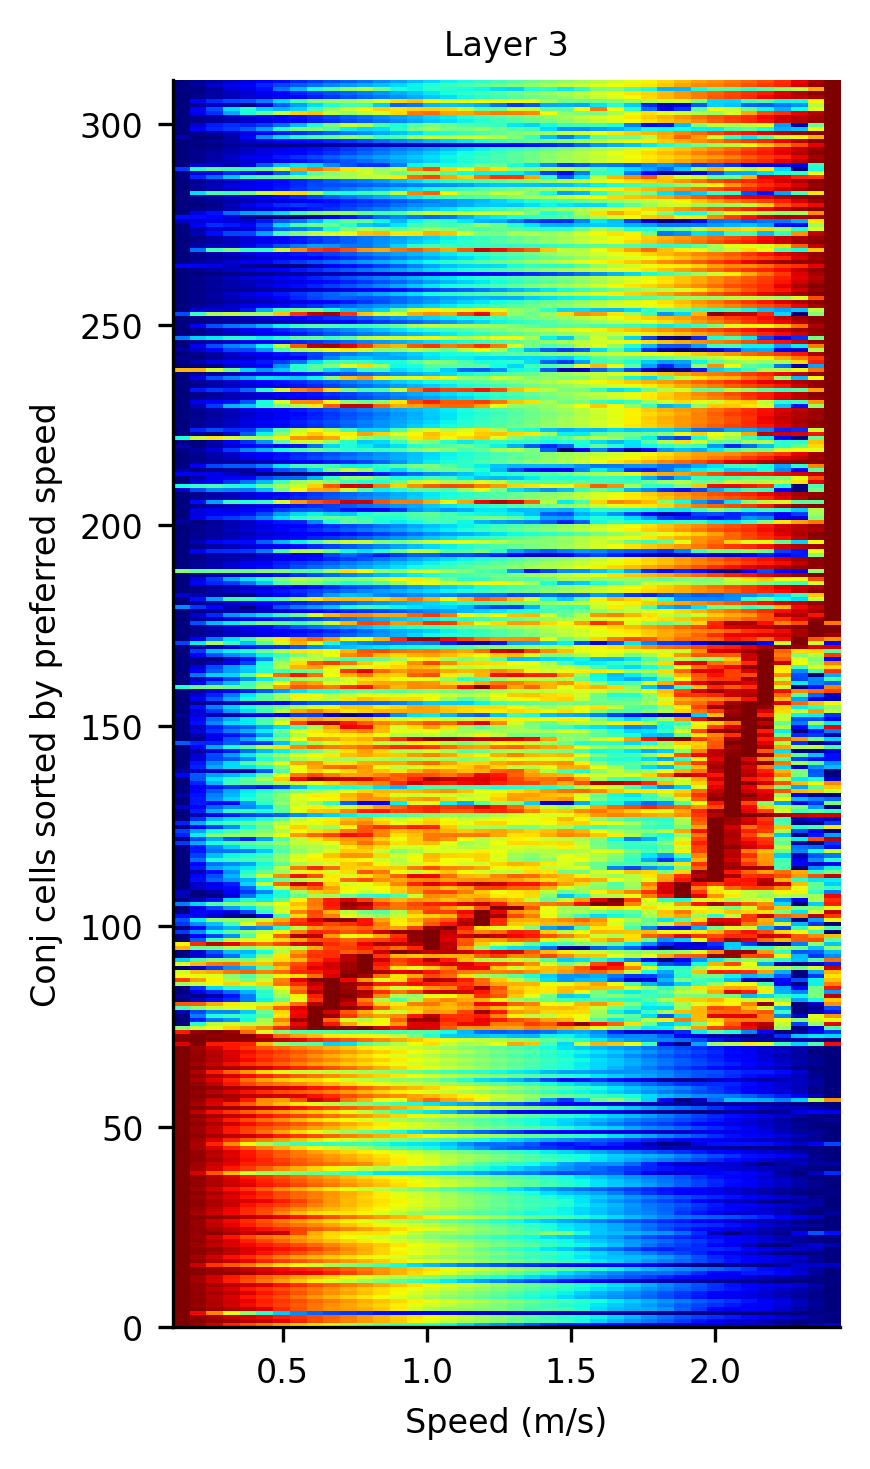

cells shown in heatmap: 460/460


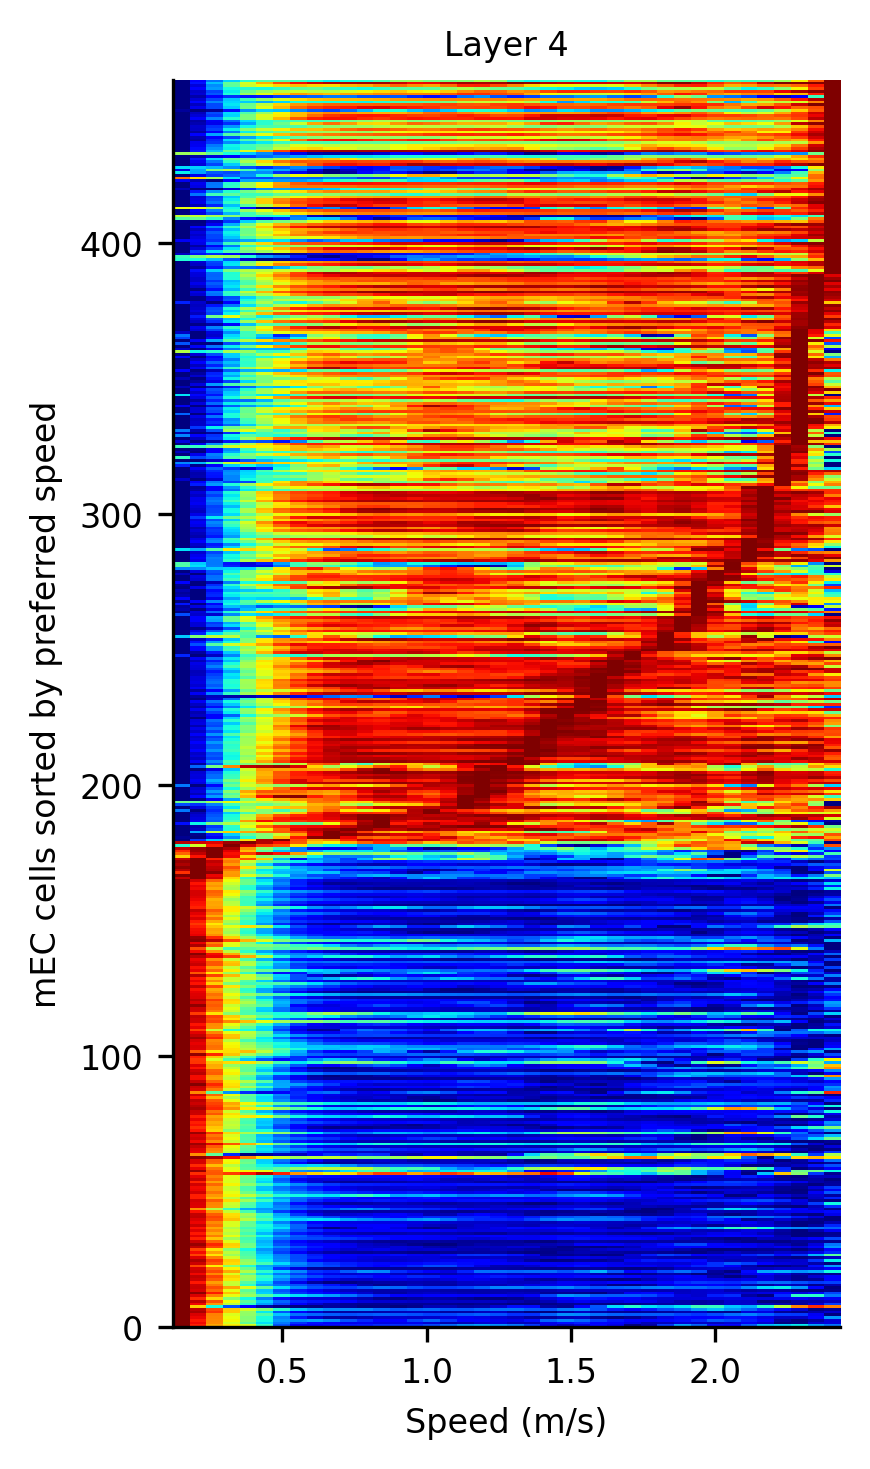

In [22]:
dt = 0.02

def plot_speed_tuning_heatmap(
    tuning,
    speed_centers,
    ylabel="Cells sorted by preferred speed",
    save_path=None,
    title=None,
):
    speed_centers_mps = speed_centers / dt

    valid_cell = np.sum(np.isfinite(tuning), axis=1) >= 2
    tuning_use = tuning[valid_cell]

    print(f"cells shown in heatmap: {tuning_use.shape[0]}/{tuning.shape[0]}")

    row_min = np.nanmin(tuning_use, axis=1, keepdims=True)
    row_max = np.nanmax(tuning_use, axis=1, keepdims=True)
    tuning_norm = (tuning_use - row_min) / (row_max - row_min + 1e-8)

    peak_idx = np.nanargmax(tuning_norm, axis=1)
    order = np.argsort(peak_idx)
    tuning_plot = tuning_norm[order]

    cmap = plt.cm.jet.copy()
    cmap.set_bad(color="#E6E6E6")

    fig, ax = plt.subplots(figsize=(3, 5), dpi=300)

    ax.imshow(
        np.ma.masked_invalid(tuning_plot),
        aspect="auto",
        cmap=cmap,
        origin="lower",
        extent=[
            speed_centers_mps[0],
            speed_centers_mps[-1],
            0,
            tuning_plot.shape[0],
        ],
        interpolation="nearest",
    )

    ax.set_xlabel("Speed (m/s)", fontsize=8)
    ax.set_ylabel(ylabel, fontsize=8)
    ax.tick_params(axis="both", labelsize=8)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if title is not None:
        ax.set_title(title, fontsize=8)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()

plot_speed_tuning_heatmap(
    tuning=conj_speed_tuning,
    speed_centers=conj_speed_centers,
    ylabel="Conj cells sorted by preferred speed",
    title="Layer 3",
    save_path="./docs/conj_speed_tuning_heatmap_nonsilent.pdf",
)


plot_speed_tuning_heatmap(
    tuning=mec_speed_tuning,
    speed_centers=mec_speed_centers,
    ylabel="mEC cells sorted by preferred speed",
    title="Layer 4",
    save_path="./docs/mEC_speed_tuning_heatmap_nonsilent.pdf",
)


#### plot 64 linear speed cells

Kept 311 cells with enough valid speed bins out of 311


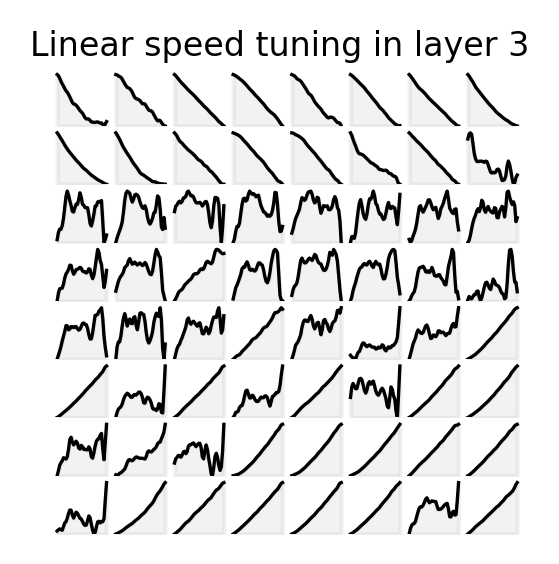

Kept 460 cells with enough valid speed bins out of 460


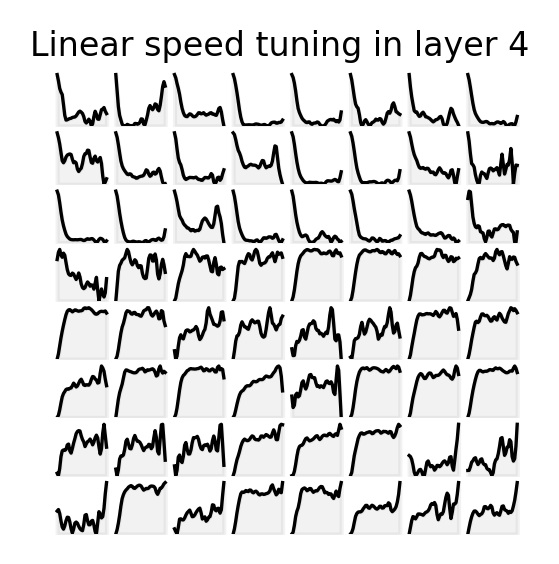

In [23]:
def normalize_1d_ignore_nan(vals):
    vals = vals.copy()
    good = np.isfinite(vals)

    if np.sum(good) < 2:
        return vals, good

    vmin = np.nanmin(vals[good])
    vmax = np.nanmax(vals[good])

    vals[good] = vals[good] - vmin
    vals[good] = vals[good] / (vmax - vmin + 1e-8)

    return vals, good


def plot_speed_tuning_64_evenly_sampled_by_preferred_speed(
    speed_tuning,
    speed_centers,
    speed_orig_ids=None,
    n_show=64,
    n_cols=8,
    normalize=True,
    min_valid_bins=3,
    save_path=None,
    title=None,
):
    # remove cells with too few valid bins
    valid_cell = np.sum(np.isfinite(speed_tuning), axis=1) >= min_valid_bins
    valid_ids = np.where(valid_cell)[0]

    if len(valid_ids) == 0:
        print("No cells with enough valid speed bins.")
        return None

    tuning_valid = speed_tuning[valid_ids].copy()

    # normalize only for finding preferred speed bin and plotting
    tuning_for_sort = np.full_like(tuning_valid, np.nan, dtype=float)

    for i in range(tuning_valid.shape[0]):
        if normalize:
            vals_norm, good = normalize_1d_ignore_nan(tuning_valid[i])
            tuning_for_sort[i] = vals_norm
        else:
            tuning_for_sort[i] = tuning_valid[i]

    # sort by preferred speed bin, low speed to high speed
    pref_idx = np.nanargmax(tuning_for_sort, axis=1)
    order_local = np.argsort(pref_idx)

    tuning_sorted = tuning_for_sort[order_local]
    ids_sorted = valid_ids[order_local]

    if speed_orig_ids is not None:
        orig_sorted = speed_orig_ids[ids_sorted]
    else:
        orig_sorted = ids_sorted

    print(
        f"Kept {tuning_sorted.shape[0]} cells with enough valid speed bins "
        f"out of {speed_tuning.shape[0]}"
    )

    if tuning_sorted.shape[0] < n_show:
        print(f"Only {tuning_sorted.shape[0]} valid cells found; plotting all of them.")
        n_show = tuning_sorted.shape[0]

    idx_show = np.linspace(
        0,
        tuning_sorted.shape[0] - 1,
        n_show,
        dtype=int,
    )

    tuning_show = tuning_sorted[idx_show]
    orig_show = orig_sorted[idx_show]

    n_rows = int(np.ceil(n_show / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(2, 2),
        dpi=300,
        squeeze=False,
    )

    for i in range(n_rows * n_cols):
        r, c = divmod(i, n_cols)
        ax = axes[r][c]

        if i < n_show:
            vals = tuning_show[i]
            good = np.isfinite(vals)

            ax.fill_between(
                speed_centers[good],
                0,
                vals[good],
                color="grey",
                alpha=0.1,
            )
            ax.plot(
                speed_centers[good],
                vals[good],
                color="black",
                linewidth=0.8,
            )

            if normalize:
                ax.set_ylim(0, 1.05)

        ax.set_xticks([])
        ax.set_yticks([])
        ax.axis("off")

    plt.subplots_adjust(wspace=0.08, hspace=0.08)

    if title is not None:
        plt.suptitle(title, fontsize=8, y=0.95)

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None


plot_speed_tuning_64_evenly_sampled_by_preferred_speed(
    speed_tuning=conj_speed_tuning,
    speed_centers=conj_speed_centers,
    speed_orig_ids=None,
    n_show=64,
    n_cols=8,
    normalize=True,
    min_valid_bins=3,
    save_path="./docs/conj_speed_tuning_64cells.pdf",
    title="Linear speed tuning in layer 3",
)

plot_speed_tuning_64_evenly_sampled_by_preferred_speed(
    speed_tuning=mec_speed_tuning,
    speed_centers=mec_speed_centers,
    speed_orig_ids=None,
    n_show=64,
    n_cols=8,
    normalize=True,
    min_valid_bins=3,
    save_path="./docs/mec_speed_tuning_64cells.pdf",
    title="Linear speed tuning in layer 4",
)




### SI: plot 512 speed cells

Kept 311 cells with enough valid speed bins out of 311
Only 311 valid cells found; plotting all of them.


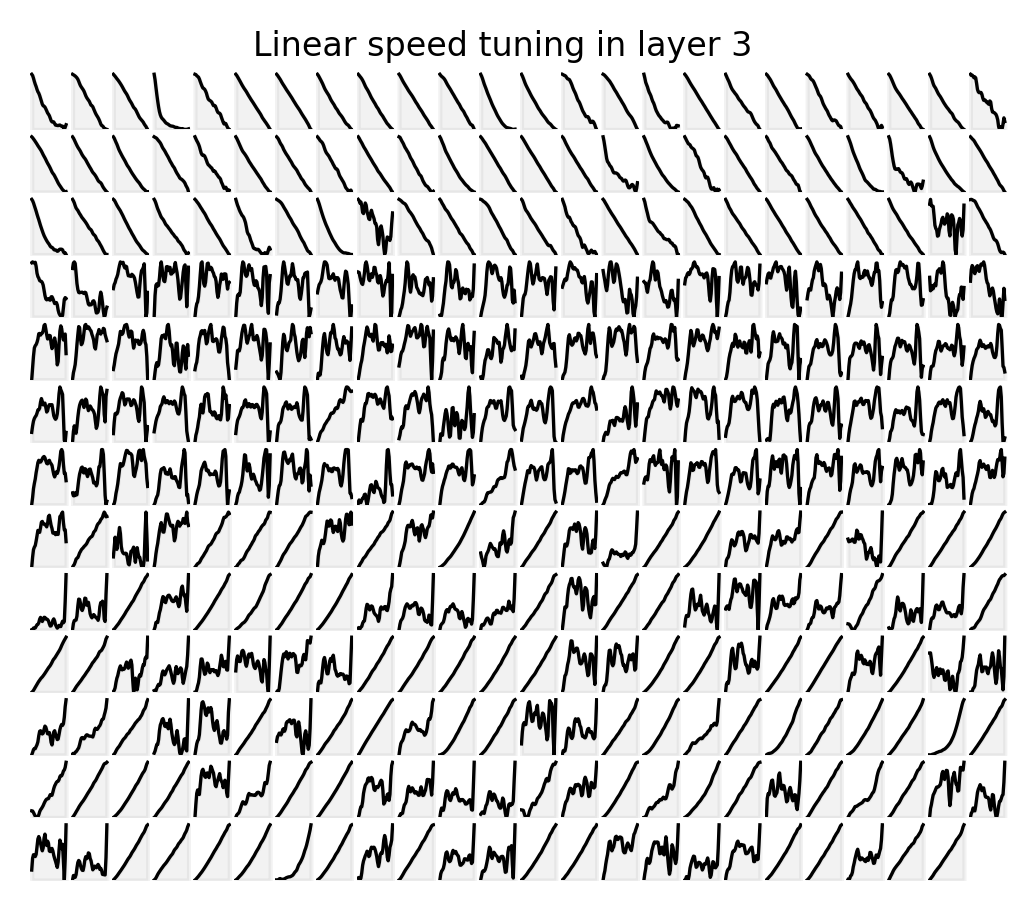

Kept 460 cells with enough valid speed bins out of 460
Only 460 valid cells found; plotting all of them.


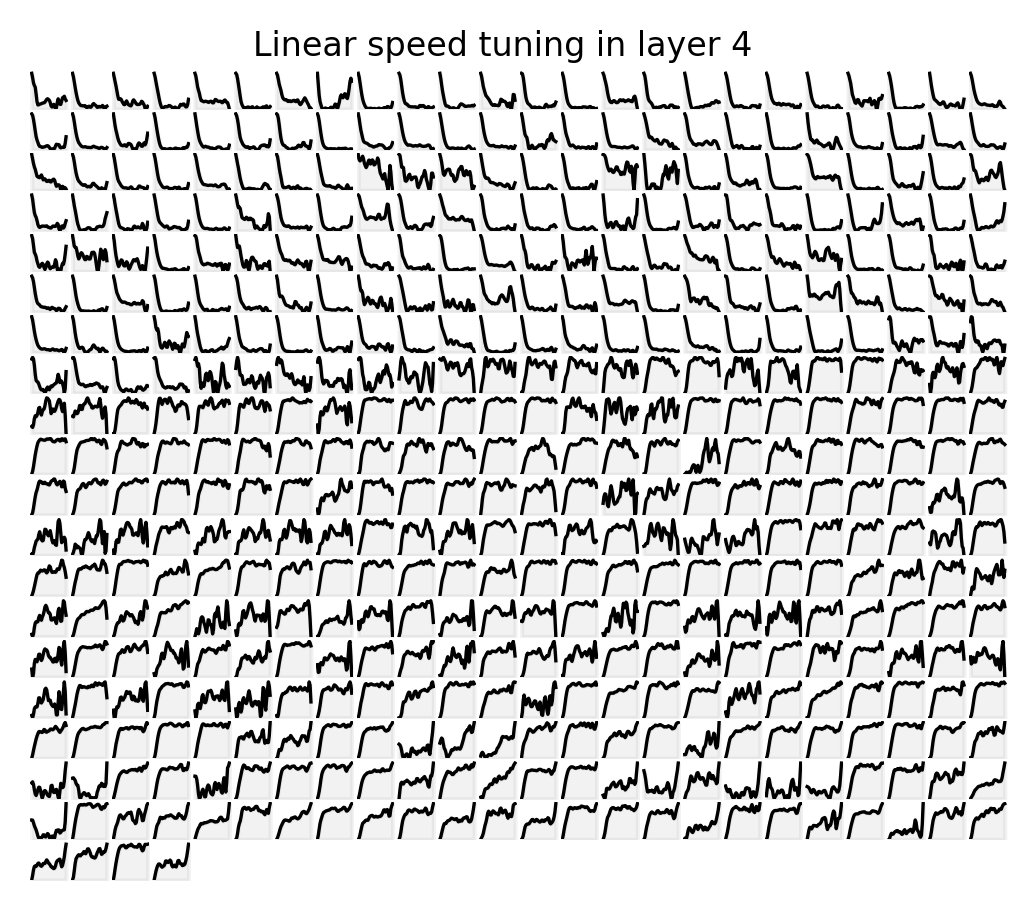

In [24]:
def normalize_1d_ignore_nan(vals):
    vals = vals.copy()
    good = np.isfinite(vals)

    if np.sum(good) < 2:
        return vals, good

    vmin = np.nanmin(vals[good])
    vmax = np.nanmax(vals[good])

    vals[good] = vals[good] - vmin
    vals[good] = vals[good] / (vmax - vmin + 1e-8)

    return vals, good


def plot_speed_tuning_64_evenly_sampled_by_preferred_speed(
    speed_tuning,
    speed_centers,
    speed_orig_ids=None,
    n_show=64,
    n_cols=8,
    normalize=True,
    min_valid_bins=3,
    save_path=None,
    title=None,
):
    # remove cells with too few valid bins
    valid_cell = np.sum(np.isfinite(speed_tuning), axis=1) >= min_valid_bins
    valid_ids = np.where(valid_cell)[0]

    if len(valid_ids) == 0:
        print("No cells with enough valid speed bins.")
        return None

    tuning_valid = speed_tuning[valid_ids].copy()

    # normalize only for finding preferred speed bin and plotting
    tuning_for_sort = np.full_like(tuning_valid, np.nan, dtype=float)

    for i in range(tuning_valid.shape[0]):
        if normalize:
            vals_norm, good = normalize_1d_ignore_nan(tuning_valid[i])
            tuning_for_sort[i] = vals_norm
        else:
            tuning_for_sort[i] = tuning_valid[i]

    # sort by preferred speed bin, low speed to high speed
    pref_idx = np.nanargmax(tuning_for_sort, axis=1)
    order_local = np.argsort(pref_idx)

    tuning_sorted = tuning_for_sort[order_local]
    ids_sorted = valid_ids[order_local]

    if speed_orig_ids is not None:
        orig_sorted = speed_orig_ids[ids_sorted]
    else:
        orig_sorted = ids_sorted

    print(
        f"Kept {tuning_sorted.shape[0]} cells with enough valid speed bins "
        f"out of {speed_tuning.shape[0]}"
    )

    if tuning_sorted.shape[0] < n_show:
        print(f"Only {tuning_sorted.shape[0]} valid cells found; plotting all of them.")
        n_show = tuning_sorted.shape[0]

    idx_show = np.linspace(
        0,
        tuning_sorted.shape[0] - 1,
        n_show,
        dtype=int,
    )

    tuning_show = tuning_sorted[idx_show]
    orig_show = orig_sorted[idx_show]

    n_rows = int(np.ceil(n_show / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(4.2, 3.5),
        dpi=300,
        squeeze=False,
    )

    for i in range(n_rows * n_cols):
        r, c = divmod(i, n_cols)
        ax = axes[r][c]

        if i < n_show:
            vals = tuning_show[i]
            good = np.isfinite(vals)

            ax.fill_between(
                speed_centers[good],
                0,
                vals[good],
                color="grey",
                alpha=0.1,
            )
            ax.plot(
                speed_centers[good],
                vals[good],
                color="black",
                linewidth=0.8,
            )

            if normalize:
                ax.set_ylim(0, 1.05)

        ax.set_xticks([])
        ax.set_yticks([])
        ax.axis("off")

    plt.subplots_adjust(wspace=0.08, hspace=0.08)

    if title is not None:
        plt.suptitle(title, fontsize=8, y=0.92)

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None


plot_speed_tuning_64_evenly_sampled_by_preferred_speed(
    speed_tuning=conj_speed_tuning,
    speed_centers=conj_speed_centers,
    speed_orig_ids=None,
    n_show=512,
    n_cols=24,
    normalize=True,
    min_valid_bins=3,
    save_path="./docs/conj_speed_tuning_all_cells_by_pref_speed.pdf",
    title="Linear speed tuning in layer 3",
)

plot_speed_tuning_64_evenly_sampled_by_preferred_speed(
    speed_tuning=mec_speed_tuning,
    speed_centers=mec_speed_centers,
    speed_orig_ids=None,
    n_show=512,
    n_cols=24,
    normalize=True,
    min_valid_bins=3,
    save_path="./docs/mec_speed_tuning_all_cells_by_pref_speed.pdf",
    title="Linear speed tuning in layer 4",
)


